# TerraWatch AI: rainfall trend, dry spells, and fire link (South Sumatra)
NASA Space Apps 2026 Jakarta. Challenge: *Be An Earth System Trend Detective!*

**Inputs (real NASA data you download yourself):**
1. Giovanni CSV: GPM IMERG Final Daily V07 (`GPM_3IMERGDF`), area-averaged, mm/day.
2. FIRMS CSV (optional until it arrives): MODIS active fire detections.

Run cells top to bottom. Nothing here is synthetic.

In [1]:
# 1. Setup and parameters
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats

DRY_MM = 1.0          # a day counts as "dry" if area-average rain < DRY_MM mm/day (documented choice)
Z_DRY = -1.5          # robust z-score below this = unusually dry month
BBOX = (102.0, -4.9, 106.2, -1.6)   # west, south, east, north (same box used in Giovanni)
CONF_MIN = 50         # MODIS confidence (0-100) minimum; 30 = nominal and above
SATELLITE = "Terra"   # Terra only gives a consistent record from 2001 (Aqua starts mid-2002)
plt.rcParams["figure.dpi"] = 110

In [2]:
# 2. Find uploaded files in Kaggle
import os
RAIN_PATH, FIRMS_PATH = None, None
for root, _, names in os.walk("/kaggle/input"):
    for n in names:
        if not n.lower().endswith(".csv"):
            continue
        p = os.path.join(root, n)
        head = open(p, errors="ignore").read(3000)
        if "GPM_3IMERGDF" in head or "Area-Averaged" in head:
            RAIN_PATH = p
        elif "acq_date" in head.lower():
            FIRMS_PATH = p
print("Rain file :", RAIN_PATH)
print("FIRMS file:", FIRMS_PATH)

Rain file : /kaggle/input/datasets/hendrikharyanto/terrawatch-rainfall/g4.areaAvgTimeSeries.GPM_3IMERGDF_07_precipitation.20000101-20241231.102E_4S_106E_1S.csv
FIRMS file: /kaggle/input/datasets/hendrikharyanto/terrawatch-fire/fire_archive_M-C61_847232.csv


In [3]:
# 3. Load rainfall and run quality checks
raw = pd.read_csv(RAIN_PATH, skiprows=8, parse_dates=["time"])
raw.columns = ["time", "p"]
fill = -9999.9
raw["p"] = raw["p"].where(raw["p"] > fill + 1)       # fill value -> NaN, never zero
s = raw.set_index("time")["p"]
full = pd.date_range(s.index.min(), s.index.max())
print("Days:", len(s), "| period:", s.index.min().date(), "to", s.index.max().date())
print("Missing days:", len(full.difference(s.index)), "| NaN:", int(s.isna().sum()), "| duplicates:", int(s.index.duplicated().sum()))
print(s.describe().round(2))

Days: 9132 | period: 2000-01-01 to 2024-12-31
Missing days: 0 | NaN: 0 | duplicates: 0
count    9132.00
mean        7.88
std         7.10
min         0.00
25%         2.20
50%         6.19
75%        11.53
max        55.92
Name: p, dtype: float64


In [4]:
# 4. Trend tests: Mann-Kendall (with tie correction) and Sen's slope
def mann_kendall(x):
    x = np.asarray(x, float); n = len(x)
    S = sum(np.sign(x[j] - x[i]) for i in range(n - 1) for j in range(i + 1, n))
    _, c = np.unique(x, return_counts=True)
    var = (n * (n - 1) * (2 * n + 5) - np.sum(c * (c - 1) * (2 * c + 5))) / 18
    z = 0.0 if S == 0 else (S - np.sign(S)) / np.sqrt(var)
    return S, var, z, 2 * (1 - stats.norm.cdf(abs(z)))

def sen(x, t):
    r = stats.theilslopes(x, t)          # slope, intercept, CI low, CI high (95%)
    return r[0], r[2], r[3], r[1]

def seasonal_mk(monthly):
    St = Vt = 0.0
    for m in range(1, 13):
        S, v, _, _ = mann_kendall(monthly[monthly.index.month == m].values)
        St += S; Vt += v
    z = (St - np.sign(St)) / np.sqrt(Vt)
    return z, 2 * (1 - stats.norm.cdf(abs(z)))

monthly = s.resample("MS").sum(min_count=28)
annual = s.resample("YS").sum(min_count=360)
annual.index = annual.index.year

rows = []
def add(name, series):
    t = np.asarray(series.index, float)
    _, _, z, p = mann_kendall(series.values)
    sl, lo, hi, _ = sen(series.values, t)
    rows.append([name, round(z, 2), round(p, 3), round(sl, 2), f"{lo:.1f} to {hi:.1f}", "Yes" if p < 0.05 else "No"])

add("Annual total (mm/yr)", annual)
for label, months in [("Dry season Jun-Sep (mm/yr)", [6, 7, 8, 9]), ("Aug-Oct (mm/yr)", [8, 9, 10])]:
    x = s[s.index.month.isin(months)]
    add(label, x.groupby(x.index.year).sum())
zs, ps = seasonal_mk(monthly.dropna())
rows.append(["Monthly, seasonal MK", round(zs, 2), round(ps, 3), "-", "-", "Yes" if ps < 0.05 else "No"])
trend_table = pd.DataFrame(rows, columns=["Series", "MK z", "p-value", "Sen slope per yr", "95% CI", "Significant (p<0.05)"])
trend_table

,Series,MK z,p-value,Sen slope per yr,95% CI,Significant (p<0.05)
0,Annual total (mm/yr),0.12,0.907,1.7,-28.6 to 24.7,No
1,Dry season Jun-Sep (mm/yr),0.26,0.797,2.01,-9.3 to 15.1,No
2,Aug-Oct (mm/yr),-0.07,0.944,-0.69,-17.0 to 16.5,No
3,"Monthly, seasonal MK",0.17,0.866,-,-,No


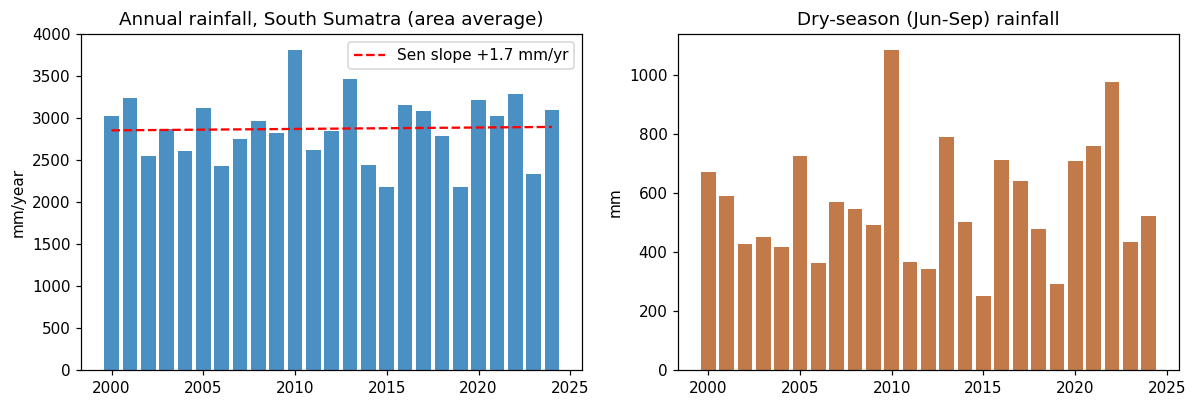

In [5]:
# 5. Plots: annual total with Sen's line, and dry-season total
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
t = annual.index.values.astype(float)
sl, lo, hi, ic = sen(annual.values, t)
ax[0].bar(annual.index, annual.values, color="#4a90c2")
ax[0].plot(t, ic + sl * t, "r--", label=f"Sen slope {sl:+.1f} mm/yr")
ax[0].set_title("Annual rainfall, South Sumatra (area average)"); ax[0].set_ylabel("mm/year"); ax[0].legend()
ds = s[s.index.month.isin([6, 7, 8, 9])]; ds = ds.groupby(ds.index.year).sum()
ax[1].bar(ds.index, ds.values, color="#c27a4a")
ax[1].set_title("Dry-season (Jun-Sep) rainfall"); ax[1].set_ylabel("mm")
plt.tight_layout(); plt.savefig("fig_trend.png"); plt.show()

Unusually dry months (z < -1.5): 25
time
2019-11-01   -4.06
2006-11-01   -3.33
2018-01-01   -2.94
2015-05-01   -2.68
2008-05-01   -2.57
2003-06-01   -2.51
2021-04-01   -2.40
2007-11-01   -2.39
2016-12-01   -2.21
2004-06-01   -2.19
2015-10-01   -2.06
2012-01-01   -2.05
Name: p, dtype: float64


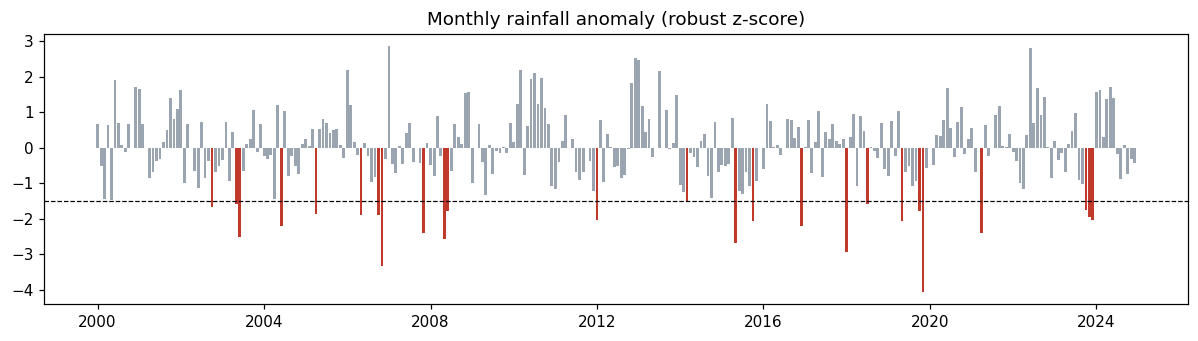

In [6]:
# 6. Anomalies: robust z-score (median/MAD) against same-calendar-month baseline
def robust_z(x):
    med = x.median(); mad = (x - med).abs().median()
    return 0.6745 * (x - med) / mad if mad > 0 else x * 0

mm = monthly.dropna()
anom = mm.groupby(mm.index.month, group_keys=False).apply(robust_z)
dry_months = anom[anom < Z_DRY]
print(f"Unusually dry months (z < {Z_DRY}): {len(dry_months)}")
print(dry_months.round(2).sort_values().head(12))

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.bar(anom.index, anom.values, width=25, color=np.where(anom.values < Z_DRY, "#c0392b", "#9aa5b1"))
ax.axhline(Z_DRY, color="k", lw=0.8, ls="--"); ax.set_title("Monthly rainfall anomaly (robust z-score)")
plt.tight_layout(); plt.savefig("fig_anomaly.png"); plt.show()

Longest dry run per year (< 1.0 mm/day, area average):
time
2006    35
2019    34
2015    22
2024    21
2023    17
2004    14
2012    13
2003    12
Name: p, dtype: int64


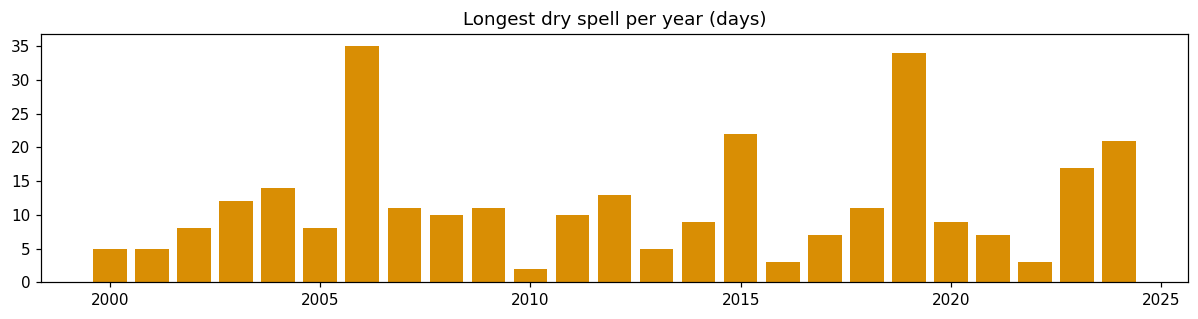

In [7]:
# 7. Dry spells: longest run of days with area-average rain < DRY_MM, per year
dry = (s < DRY_MM)
run_id = (dry != dry.shift()).cumsum()
run_len = dry.groupby(run_id).transform("sum") * dry
longest = run_len.groupby(run_len.index.year).max()
print(f"Longest dry run per year (< {DRY_MM} mm/day, area average):")
print(longest.sort_values(ascending=False).head(8))
fig, ax = plt.subplots(figsize=(11, 3)); ax.bar(longest.index, longest.values, color="#d98e04")
ax.set_title("Longest dry spell per year (days)"); plt.tight_layout(); plt.savefig("fig_dryspell.png"); plt.show()

## Fire link (needs the FIRMS CSV)
Cells below run only if a FIRMS file was uploaded. **Why Terra only:** MODIS on Terra starts in late 2000 and Aqua in mid-2002, so combining both makes counts rise only because more satellites were flying. Using one satellite keeps the record consistent.

In [8]:
# 8. Load and filter FIRMS (skip if no file)
if FIRMS_PATH is None:
    print("No FIRMS file uploaded yet. Upload it and re-run from cell 2.")
else:
    f = pd.read_csv(FIRMS_PATH)
    f.columns = [c.strip().lower() for c in f.columns]
    print("Columns:", list(f.columns)); print("Rows:", len(f))
    f["acq_date"] = pd.to_datetime(f["acq_date"])
    w, so, e, n = BBOX
    f = f[(f.longitude.between(w, e)) & (f.latitude.between(so, n))]
    if "satellite" in f.columns: f = f[f["satellite"].astype(str).str.contains(SATELLITE, case=False)]
    if "confidence" in f.columns: f = f[pd.to_numeric(f["confidence"], errors="coerce") >= CONF_MIN]
    if "type" in f.columns: f = f[f["type"] == 0]          # presumed vegetation fire
    f = f.drop_duplicates(["latitude", "longitude", "acq_date", "acq_time"] if "acq_time" in f.columns else None)
    f = f[(f.acq_date >= "2001-01-01") & (f.acq_date <= "2024-12-31")]
    print("Detections kept:", len(f), "| filters: bbox, satellite =", SATELLITE, ", confidence >=", CONF_MIN, ", type = 0 if present")

Columns: ['latitude', 'longitude', 'brightness', 'scan', 'track', 'acq_date', 'acq_time', 'satellite', 'instrument', 'confidence', 'version', 'bright_t31', 'frp', 'daynight', 'type']
Rows: 225736
Detections kept: 45972 | filters: bbox, satellite = Terra , confidence >= 50 , type = 0 if present


Spearman rain_AugOct vs fires_AugOct: rho=-0.92, p=0.000, n=24
Spearman longest_dry vs fires_AugOct: rho=0.78, p=0.000, n=24
      rain_AugOct  longest_dry  fires_AugOct
2015   122.684286           22        7531.0
2006   135.661793           35        5510.0
2019   123.255664           34        4011.0
2012   347.309493           13        3118.0
2011   354.240749           10        2772.0
2002   217.035693            8        2259.0
2014   326.110385            9        2255.0
2004   357.169517           14        2221.0


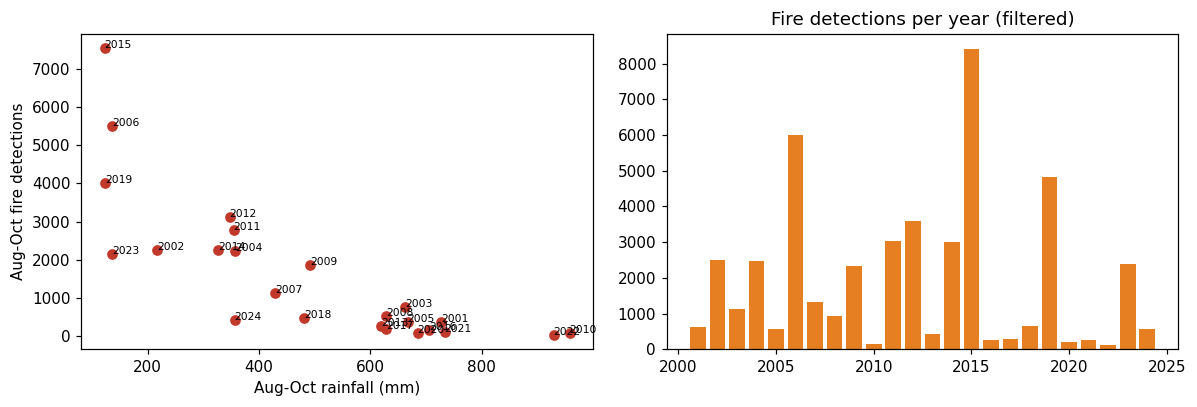

In [9]:
# 9. Link rainfall to fire detections (Spearman rank correlation, no causal claim)
if FIRMS_PATH is not None:
    fy = f.groupby(f.acq_date.dt.year).size().rename("fires")
    fire_season = f[f.acq_date.dt.month.isin([8, 9, 10])]
    fs = fire_season.groupby(fire_season.acq_date.dt.year).size().rename("fires_AugOct")
    ao = s[s.index.month.isin([8, 9, 10])]; ao = ao.groupby(ao.index.year).sum().rename("rain_AugOct")
    j = pd.concat([ao, longest.rename("longest_dry"), fs], axis=1).dropna()
    for a, b in [("rain_AugOct", "fires_AugOct"), ("longest_dry", "fires_AugOct")]:
        r, p = stats.spearmanr(j[a], j[b]); print(f"Spearman {a} vs {b}: rho={r:.2f}, p={p:.3f}, n={len(j)}")
    print(j.sort_values("fires_AugOct", ascending=False).head(8))
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    ax[0].scatter(j.rain_AugOct, j.fires_AugOct, c="#c0392b"); ax[0].set_xlabel("Aug-Oct rainfall (mm)"); ax[0].set_ylabel("Aug-Oct fire detections")
    for yr, row in j.iterrows(): ax[0].annotate(str(yr), (row.rain_AugOct, row.fires_AugOct), fontsize=7)
    ax[1].bar(fy.index, fy.values, color="#e67e22"); ax[1].set_title("Fire detections per year (filtered)")
    plt.tight_layout(); plt.savefig("fig_fire_link.png"); plt.show()

In [10]:
# 10. Soil moisture (MERRA-2 model reanalysis, monthly, area average)
import os
SM_PATH = None
for root, _, names in os.walk("/kaggle/input"):
    for n in names:
        if "GWETPROF" in n and n.lower().endswith(".csv"):
            SM_PATH = os.path.join(root, n)
print("Soil moisture file:", SM_PATH)

sm = pd.read_csv(SM_PATH, skiprows=8, parse_dates=["time"])
sm.columns = ["time", "sm"]
sm["sm"] = sm["sm"].where(sm["sm"] < 1e10)
sm = sm.set_index("time")["sm"]
print("Months:", len(sm), "| NaN:", int(sm.isna().sum()))

sm_year = sm.groupby(sm.index.year).mean()
_, _, z, p = mann_kendall(sm_year.values)
slope, lo, hi, _ = sen(sm_year.values, sm_year.index.values.astype(float))
print(f"Annual soil wetness: MK z={z:.2f}, p={p:.3f}, Sen={slope:+.4f}/yr (CI {lo:+.4f} to {hi:+.4f})")

sm_ao = sm[sm.index.month.isin([8, 9, 10])]
sm_ao = sm_ao.groupby(sm_ao.index.year).mean().rename("sm_AugOct")
print(sm_ao.sort_values().head(6).round(3))

if FIRMS_PATH is not None:
    j2 = pd.concat([sm_ao, ao, fs], axis=1).dropna()
    r, p = stats.spearmanr(j2["sm_AugOct"], j2["fires_AugOct"])
    print(f"Soil wetness vs Aug-Oct fires: rho={r:.2f}, p={p:.3f}, n={len(j2)}")
    r2, p2 = stats.spearmanr(j2["sm_AugOct"], j2["rain_AugOct"])
    print(f"Soil wetness vs Aug-Oct rainfall: rho={r2:.2f}, p={p2:.3f}")

Soil moisture file: /kaggle/input/datasets/hendrikharyanto/soil-moisture/g4.areaAvgTimeSeries.M2TMNXLND_5_12_4_GWETPROF.20000101-20241231.102E_4S_106E_1S.csv
Months: 300 | NaN: 0
Annual soil wetness: MK z=1.42, p=0.154, Sen=+0.0024/yr (CI -0.0006 to +0.0053)
time
2015    0.638
2003    0.661
2019    0.670
2002    0.696
2012    0.714
2006    0.723
Name: sm_AugOct, dtype: float64
Soil wetness vs Aug-Oct fires: rho=-0.88, p=0.000, n=24
Soil wetness vs Aug-Oct rainfall: rho=0.76, p=0.000


In [11]:
f["version"].value_counts()

version
6.03     43016
61.03     2956
Name: count, dtype: int64

In [12]:
# 11. Build the ML table (no future information in any feature)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (average_precision_score, brier_score_loss, roc_auc_score,
                             f1_score, precision_score, recall_score, confusion_matrix,
                             precision_recall_curve)
from sklearn.inspection import permutation_importance
try:
    from xgboost import XGBClassifier
    HAVE_XGB = True
except Exception:
    HAVE_XGB = False
print("XGBoost available:", HAVE_XGB)

ML_START, HORIZON, STRIDE, HIGH_Q = "2003-01-01", 7, 7, 0.85
TRAIN_END, VAL_END = "2018-12-31", "2021-12-31"
# Known FIRMS MODIS gaps from the download README (exact end dates not given, so windows are generous)
GAPS = [("2007-08-10", "2007-09-15"), ("2009-04-20", "2009-04-23")]

days = pd.date_range(ML_START, "2024-12-31")
all_days = pd.date_range("2001-01-01", "2024-12-31")
fires_full = f.groupby("acq_date").size().reindex(all_days, fill_value=0).astype(float)

X = pd.DataFrame(index=days)
for w in (7, 30, 60, 90):
    X[f"rain_{w}d"] = s.rolling(w).sum().reindex(days)
dry = (s < DRY_MM)
grp = (dry != dry.shift()).cumsum()
X["dry_run"] = (dry.groupby(grp).cumsum() * dry).reindex(days)          # consecutive dry days ending at t
X["log_fire_7d"] = np.log1p(fires_full.rolling(7).sum()).reindex(days)    # fires up to and including day t
X["log_fire_30d"] = np.log1p(fires_full.rolling(30).sum()).reindex(days)
month_val = dict(zip(sm.index.to_period("M"), sm.values))
X["sm_prev"] = [month_val.get(p, np.nan) for p in (days.to_period("M") - 1)]   # last COMPLETED month only
doy = days.dayofyear.values
X["doy_sin"], X["doy_cos"] = np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)

fut7 = fires_full.rolling(HORIZON).sum().shift(-HORIZON).reindex(days)     # detections on t+1 ... t+7
D = X.join(fut7.rename("fut7")).dropna()
bad = pd.Series(False, index=D.index)
for a, b in GAPS:
    bad |= (D.index >= pd.Timestamp(a) - pd.Timedelta(days=30)) & (D.index <= pd.Timestamp(b))
D = D[~bad]
D = D[((D.index - D.index[0]).days % STRIDE) == 0]                          # one prediction per week

gap = pd.Timedelta(days=HORIZON)
tr = D[D.index <= pd.Timestamp(TRAIN_END) - gap].copy()
va = D[(D.index > TRAIN_END) & (D.index <= pd.Timestamp(VAL_END) - gap)].copy()
te = D[D.index > VAL_END].copy()
thr = max(tr["fut7"].quantile(HIGH_Q), 1)
for d_ in (tr, va, te):
    d_["y"] = (d_["fut7"] >= thr).astype(int)
print(f"High-activity threshold (train {int(HIGH_Q*100)}th percentile): {thr:.0f} detections in 7 days")
for name, d_ in [("train", tr), ("val", va), ("test", te)]:
    print(f"{name:5s}: {len(d_):4d} weeks, positives {int(d_.y.sum()):3d} ({d_.y.mean():.2f})")

SEASON = ["doy_sin", "doy_cos"]
FIRE = ["log_fire_7d", "log_fire_30d"]
ENV = SEASON + ["rain_7d", "rain_30d", "rain_60d", "rain_90d", "dry_run", "sm_prev"]
FEATURE_SETS = {"1 season only": SEASON, "2 season + fire history": SEASON + FIRE,
                "3 season + rain + soil": ENV, "4 all (env + fire history)": ENV + FIRE}


XGBoost available: True
High-activity threshold (train 85th percentile): 44 detections in 7 days
train:  819 weeks, positives 125 (0.15)
val  :  156 weeks, positives  17 (0.11)
test :  155 weeks, positives  16 (0.10)


In [13]:
# 12. Train and compare (chronological). Validation picks the winner; test is reported once.
def make_models(pos_rate):
    m = {
        "LogReg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")),
        "RandForest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced_subsample",
                                             random_state=0, n_jobs=-1),
    }
    if HAVE_XGB:
        m["XGBoost"] = XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, subsample=0.8,
                                     colsample_bytree=0.8, scale_pos_weight=(1 - pos_rate) / max(pos_rate, 1e-6),
                                     eval_metric="logloss", random_state=0, n_jobs=2)
    return m

results, preds = [], {}
for fs_name, cols in FEATURE_SETS.items():
    for mname, model in make_models(tr.y.mean()).items():
        model.fit(tr[cols], tr.y)
        pv, pt = model.predict_proba(va[cols])[:, 1], model.predict_proba(te[cols])[:, 1]
        preds[(fs_name, mname)] = (model, cols, pv, pt)
        results.append({"features": fs_name, "model": mname,
                        "val PR-AUC": average_precision_score(va.y, pv), "test PR-AUC": average_precision_score(te.y, pt),
                        "val ROC-AUC": roc_auc_score(va.y, pv), "test ROC-AUC": roc_auc_score(te.y, pt)})
res = pd.DataFrame(results).round(3).sort_values("val PR-AUC", ascending=False)
print(f"Reference: PR-AUC of a model with no skill = positive rate (val {va.y.mean():.2f}, test {te.y.mean():.2f})")
res



Reference: PR-AUC of a model with no skill = positive rate (val 0.11, test 0.10)


,features,model,val PR-AUC,test PR-AUC,val ROC-AUC,test ROC-AUC
7,3 season + rain + soil,RandForest,0.987,0.807,0.998,0.979
10,4 all (env + fire history),RandForest,0.981,0.919,0.997,0.987
8,3 season + rain + soil,XGBoost,0.978,0.791,0.996,0.977
3,2 season + fire history,LogReg,0.976,0.892,0.995,0.984
5,2 season + fire history,XGBoost,0.973,0.817,0.994,0.969
11,4 all (env + fire history),XGBoost,0.972,0.865,0.994,0.980
9,4 all (env + fire history),LogReg,0.968,0.835,0.993,0.986
4,2 season + fire history,RandForest,0.965,0.875,0.989,0.981
6,3 season + rain + soil,LogReg,0.941,0.797,0.990,0.981
0,1 season only,LogReg,0.342,0.433,0.861,0.874


Selected on validation: ('3 season + rain + soil', 'RandForest')
Threshold 0.93 (from validation). TEST: precision=0.92, recall=0.69, F1=0.79
Confusion matrix on test [[TN FP],[FN TP]]:
[[138   1]
 [  5  11]]
Brier score on test: raw=0.053, calibrated=0.031, always-predict-base-rate=0.095
Permutation importance on validation (drop in PR-AUC when shuffled):
rain_60d    0.150
rain_90d    0.127
rain_30d    0.081
doy_sin     0.038
dry_run     0.006
doy_cos     0.006
rain_7d     0.004
sm_prev     0.001
dtype: float64


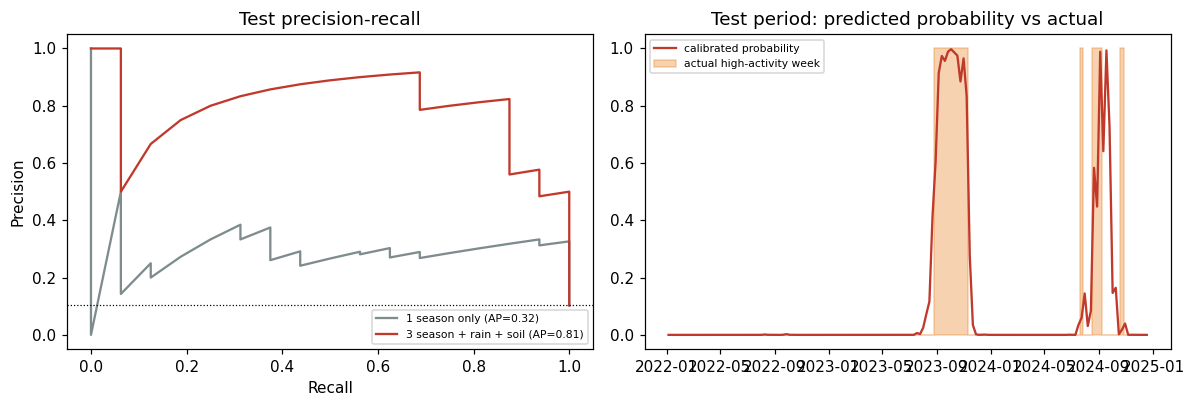

In [14]:
# 13. Best model by VALIDATION PR-AUC: threshold, calibration, test result, importance
best = res.iloc[0]; key = (best["features"], best["model"])
model, cols, pv, pt = preds[key]
print("Selected on validation:", key)

# threshold that maximises F1 on validation, applied unchanged to test
prec, rec, ths = precision_recall_curve(va.y, pv)
f1s = 2 * prec * rec / np.maximum(prec + rec, 1e-9)
t_star = ths[np.argmax(f1s[:-1])]
yhat = (pt >= t_star).astype(int)
print(f"Threshold {t_star:.2f} (from validation). TEST: precision={precision_score(te.y, yhat, zero_division=0):.2f}, "
      f"recall={recall_score(te.y, yhat):.2f}, F1={f1_score(te.y, yhat):.2f}")
print("Confusion matrix on test [[TN FP],[FN TP]]:"); print(confusion_matrix(te.y, yhat))

# Platt scaling fitted on validation predictions, then applied to test probabilities
logit = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))
platt = LogisticRegression().fit(logit(pv).reshape(-1, 1), va.y)
pt_cal = platt.predict_proba(logit(pt).reshape(-1, 1))[:, 1]
print(f"Brier score on test: raw={brier_score_loss(te.y, pt):.3f}, calibrated={brier_score_loss(te.y, pt_cal):.3f}, "
      f"always-predict-base-rate={brier_score_loss(te.y, np.full(len(te), tr.y.mean())):.3f}")

pi = permutation_importance(model, va[cols], va.y, scoring="average_precision", n_repeats=20, random_state=0)
imp = pd.Series(pi.importances_mean, index=cols).sort_values(ascending=False).round(3)
print("Permutation importance on validation (drop in PR-AUC when shuffled):"); print(imp)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for fs_name, c in [("1 season only", "#7f8c8d"), (key[0], "#c0392b")]:
    p_ = preds[(fs_name, key[1])][3]; pr, rc, _ = precision_recall_curve(te.y, p_)
    ax[0].plot(rc, pr, color=c, label=f"{fs_name} (AP={average_precision_score(te.y, p_):.2f})")
ax[0].axhline(te.y.mean(), color="k", ls=":", lw=0.8); ax[0].set_xlabel("Recall"); ax[0].set_ylabel("Precision")
ax[0].set_title("Test precision-recall"); ax[0].legend(fontsize=7)
ax[1].plot(te.index, pt_cal, color="#c0392b", label="calibrated probability")
ax[1].fill_between(te.index, 0, te.y, color="#e67e22", alpha=0.35, step="mid", label="actual high-activity week")
ax[1].set_title("Test period: predicted probability vs actual"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig("fig_ml.png"); plt.show()


Leave-one-year-out, pooled over all held-out years (no-skill PR-AUC = positive rate):
     model             features  pooled PR-AUC  pooled ROC-AUC  positive rate  weeks
RandForest          season only          0.441           0.868           0.15   1132
RandForest season + rain + soil          0.861           0.970           0.15   1132
RandForest                  all          0.881           0.974           0.15   1132
    LogReg          season only          0.444           0.880           0.15   1132
    LogReg season + rain + soil          0.806           0.967           0.15   1132
    LogReg                  all          0.848           0.973           0.15   1132
RandForest: PR-AUC gain of (season + rain + soil) over season only = +0.40 (95% year-bootstrap +0.26 to +0.52)
LogReg: PR-AUC gain of (season + rain + soil) over season only = +0.35 (95% year-bootstrap +0.22 to +0.49)

Per-year average precision (RandForest), years with >= 3 high-activity weeks:
 year  high weeks  sea

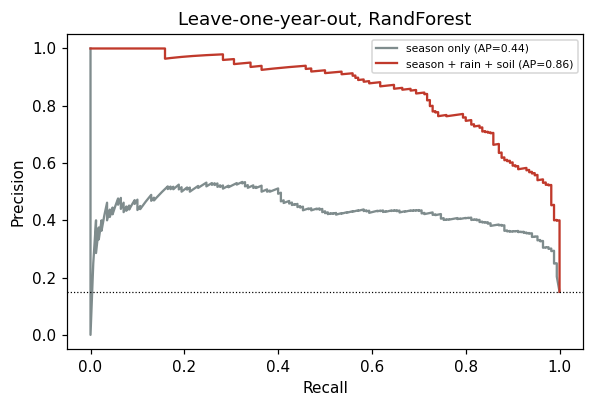

In [15]:
# 14. Leave-one-year-out check: each year 2003-2024 is held out in turn (more independent episodes than the 2022-2024 test alone)
# Note: training folds may include years AFTER the held-out year, so this estimates skill across years, it is not a forecasting simulation.
# The high-activity threshold is recomputed from each training fold. A 7-day embargo before the held-out year prevents target overlap.
Dall = D.copy()
Dall["year"] = Dall.index.year
LOYO_SETS = {"season only": SEASON, "season + rain + soil": ENV, "all": ENV + FIRE}

def make_loyo_model(name):
    if name == "RandForest":
        return RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight="balanced_subsample",
                                      random_state=0, n_jobs=-1)
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced"))

pool = {}
for mname in ("RandForest", "LogReg"):
    for sname, cols in LOYO_SETS.items():
        out = []
        for yr in sorted(Dall.year.unique()):
            te_ = Dall[Dall.year == yr]
            start = te_.index.min()
            tr_ = Dall[(Dall.year != yr) & ~((Dall.index >= start - gap) & (Dall.index < start))]
            thr_ = max(tr_["fut7"].quantile(HIGH_Q), 1)
            m = make_loyo_model(mname).fit(tr_[cols], (tr_["fut7"] >= thr_).astype(int))
            out.append(pd.DataFrame({"year": yr, "y": (te_["fut7"] >= thr_).astype(int).values,
                                     "p": m.predict_proba(te_[cols])[:, 1]}))
        pool[(mname, sname)] = pd.concat(out)

rows = []
for (mname, sname), d_ in pool.items():
    rows.append({"model": mname, "features": sname, "pooled PR-AUC": average_precision_score(d_.y, d_.p),
                 "pooled ROC-AUC": roc_auc_score(d_.y, d_.p), "positive rate": d_.y.mean(), "weeks": len(d_)})
loyo = pd.DataFrame(rows).round(3)
print("Leave-one-year-out, pooled over all held-out years (no-skill PR-AUC = positive rate):")
print(loyo.to_string(index=False))

# Uncertainty: resample YEARS (not weeks), because weeks inside a year are strongly dependent
rng = np.random.default_rng(0)
years = np.array(sorted(Dall.year.unique()))
def boot_diff(a, b, n=300):
    ga, gb = dict(tuple(a.groupby("year"))), dict(tuple(b.groupby("year")))
    diffs = []
    for _ in range(n):
        ys = rng.choice(years, len(years), replace=True)
        A, B = pd.concat([ga[y] for y in ys]), pd.concat([gb[y] for y in ys])
        if A.y.sum() == 0:
            continue
        diffs.append(average_precision_score(A.y, A.p) - average_precision_score(B.y, B.p))
    return np.percentile(diffs, [2.5, 50, 97.5])

for mname in ("RandForest", "LogReg"):
    lo, mid, hi = boot_diff(pool[(mname, "season + rain + soil")], pool[(mname, "season only")])
    print(f"{mname}: PR-AUC gain of (season + rain + soil) over season only = {mid:+.2f} (95% year-bootstrap {lo:+.2f} to {hi:+.2f})")

# Per-year view (RandForest), only years with at least 3 high-activity weeks
tab = []
for yr in years:
    r = {"year": yr, "high weeks": int(pool[("RandForest", "season only")].query("year == @yr").y.sum())}
    if r["high weeks"] >= 3:
        for sname in LOYO_SETS:
            d_ = pool[("RandForest", sname)].query("year == @yr")
            r[sname] = round(average_precision_score(d_.y, d_.p), 2)
        tab.append(r)
print("\nPer-year average precision (RandForest), years with >= 3 high-activity weeks:")
print(pd.DataFrame(tab).to_string(index=False))

fig, ax = plt.subplots(figsize=(5.5, 3.8))
for sname, c in [("season only", "#7f8c8d"), ("season + rain + soil", "#c0392b")]:
    d_ = pool[("RandForest", sname)]
    pr, rc, _ = precision_recall_curve(d_.y, d_.p)
    ax.plot(rc, pr, color=c, label=f"{sname} (AP={average_precision_score(d_.y, d_.p):.2f})")
ax.axhline(pool[("RandForest", "season only")].y.mean(), color="k", ls=":", lw=0.8)
ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_title("Leave-one-year-out, RandForest"); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig("fig_loyo.png"); plt.show()


In [16]:
# 15. Walk-forward evaluation (expanding window): for each year Y, train ONLY on earlier years, then predict Y.
# This mimics real use (the model never sees the future) and gives 15 forecast years instead of one test period.
WF_YEARS = list(range(2010, 2025))
WF_SETS = {"season only": SEASON, "season + rain + soil": ENV, "all": ENV + FIRE}

def rf_model():
    return RandomForestClassifier(n_estimators=150, min_samples_leaf=5, class_weight="balanced_subsample",
                                  random_state=0, n_jobs=-1)

def walk_forward(high_q, sets):
    pooled = {k: [] for k in sets}
    for yr in WF_YEARS:
        te_ = Dall[Dall.year == yr]
        tr_ = Dall[Dall.index < te_.index.min() - gap]              # past only, with a 7-day gap
        thr_ = max(tr_["fut7"].quantile(high_q), 1)                  # threshold from past data only
        ytr = (tr_["fut7"] >= thr_).astype(int)
        for k, cols in sets.items():
            m = rf_model().fit(tr_[cols], ytr)
            pooled[k].append(pd.DataFrame({"date": te_.index, "year": yr, "fut7": te_["fut7"].values,
                                           "y": (te_["fut7"] >= thr_).astype(int).values,
                                           "p": m.predict_proba(te_[cols])[:, 1]}))
    return {k: pd.concat(v) for k, v in pooled.items()}

def boot_gain(a, b, years_, n=300):
    ga, gb = dict(tuple(a.groupby("year"))), dict(tuple(b.groupby("year")))
    rng_, diffs = np.random.default_rng(1), []
    for _ in range(n):
        ys = rng_.choice(years_, len(years_), replace=True)
        A, B = pd.concat([ga[y] for y in ys]), pd.concat([gb[y] for y in ys])
        if A.y.sum() == 0:
            continue
        diffs.append(average_precision_score(A.y, A.p) - average_precision_score(B.y, B.p))
    return np.percentile(diffs, [2.5, 50, 97.5])

wf = walk_forward(HIGH_Q, WF_SETS)
rows = [{"features": k, "PR-AUC": average_precision_score(v.y, v.p), "ROC-AUC": roc_auc_score(v.y, v.p),
         "positive rate": v.y.mean(), "weeks": len(v)} for k, v in wf.items()]
print(f"WALK-FORWARD {WF_YEARS[0]}-{WF_YEARS[-1]} (Random Forest, train on past only). No-skill PR-AUC = positive rate.")
print(pd.DataFrame(rows).round(3).to_string(index=False))
lo, mid, hi = boot_gain(wf["season + rain + soil"], wf["season only"], np.array(WF_YEARS))
print(f"Gain of (season + rain + soil) over season only: {mid:+.2f} PR-AUC (95% year-bootstrap {lo:+.2f} to {hi:+.2f})")

tab = []
for yr in WF_YEARS:
    r = {"year": yr, "high weeks": int(wf["season only"].query("year == @yr").y.sum())}
    if r["high weeks"] >= 3:
        for k in WF_SETS:
            d_ = wf[k].query("year == @yr"); r[k] = round(average_precision_score(d_.y, d_.p), 2)
        tab.append(r)
print("\nPer-year average precision, years with >= 3 high-activity weeks:")
print(pd.DataFrame(tab).to_string(index=False))

# Calibration: each year is calibrated with Platt scaling fitted on the OTHER years' out-of-sample predictions
env = wf["season + rain + soil"].reset_index(drop=True)
cal = np.zeros(len(env))
for yr in WF_YEARS:
    oth, cur = env[env.year != yr], env.year == yr
    pl = LogisticRegression().fit(logit(oth.p.values).reshape(-1, 1), oth.y)
    cal[cur.values] = pl.predict_proba(logit(env.loc[cur, "p"].values).reshape(-1, 1))[:, 1]
env["pc"] = cal
print(f"\nBrier: raw={brier_score_loss(env.y, env.p):.3f}, calibrated={brier_score_loss(env.y, env.pc):.3f}, "
      f"base-rate={brier_score_loss(env.y, np.full(len(env), env.y.mean())):.3f}")
bins = pd.cut(env.pc, [0, .1, .2, .3, .5, .7, .9, 1.0], include_lowest=True)
rel = env.groupby(bins, observed=True).agg(weeks=("y", "size"), mean_predicted=("pc", "mean"), observed_rate=("y", "mean")).round(2)
print("Reliability table (calibrated probability vs how often high activity really followed):"); print(rel)


WALK-FORWARD 2010-2024 (Random Forest, train on past only). No-skill PR-AUC = positive rate.
            features  PR-AUC  ROC-AUC  positive rate  weeks
         season only   0.367    0.868          0.119    781
season + rain + soil   0.866    0.980          0.119    781
                 all   0.905    0.983          0.119    781
Gain of (season + rain + soil) over season only: +0.47 PR-AUC (95% year-bootstrap +0.31 to +0.63)

Per-year average precision, years with >= 3 high-activity weeks:
 year  high weeks  season only  season + rain + soil  all
 2011          12         0.99                  0.88 0.89
 2012          15         0.94                  0.97 0.97
 2014          12         0.59                  0.94 0.94
 2015          16         0.81                  0.93 0.92
 2018           3         0.49                  0.30 0.23
 2019          17         0.92                  0.99 0.99
 2023          12         0.64                  1.00 1.00
 2024           5         0.28         

Alarm rule: calibrated probability >= 0.5. Episodes = runs of high-activity weeks (gaps <= 2 weeks merged).
     start  weeks  peak 7-day detections  first alarm lead (weeks)
2011-07-20     13                    698                      -1.0
2012-06-20     17                    448                      -6.0
2013-08-21      1                    100                       NaN
2014-07-23      1                     65                      -1.0
2014-08-27     11                    618                       4.0
2015-06-24     20                   1213                      -5.0
2018-08-15      1                     77                       2.0
2018-09-12      3                     99                       4.0
2019-07-24     17                    935                      -1.0
2023-08-23     12                    479                       0.0
2024-07-24      1                     49                       NaN
2024-08-21      3                     74                       0.0
2024-10-23      1    

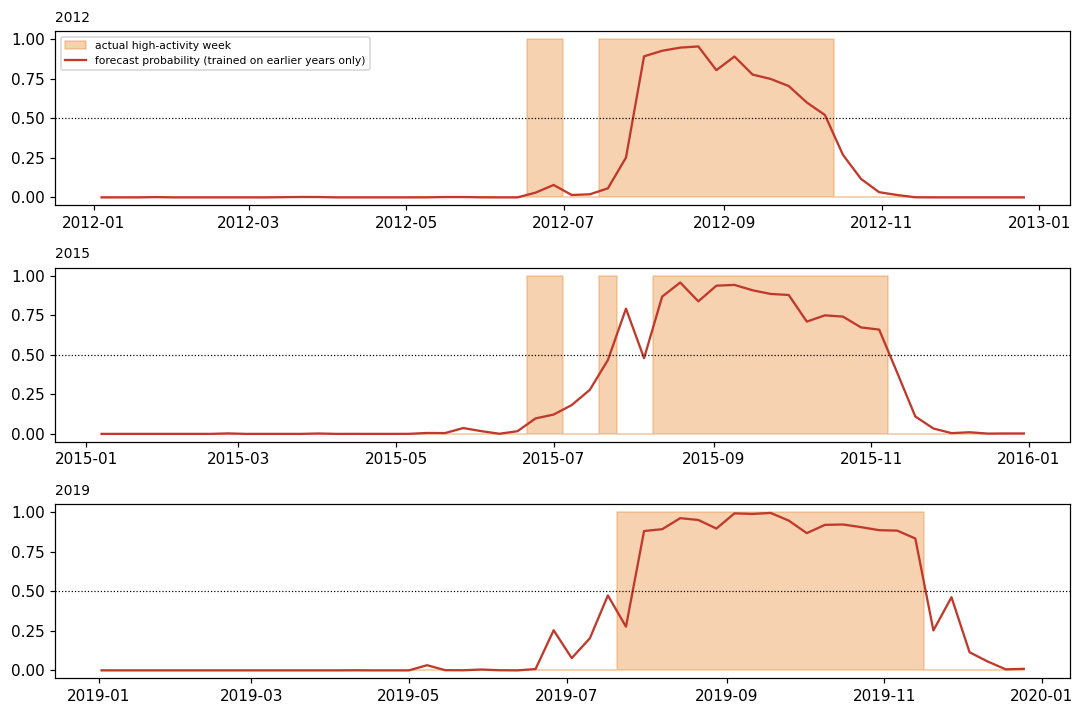

In [17]:
# 16. Episode-level view: does the model warn BEFORE a high-activity episode starts, and how many false alarms?
ALARM_P = 0.5            # fixed in advance on the calibrated probability (not tuned on these results)
env = env.sort_values("date").reset_index(drop=True)
hi_idx = list(env.index[env.y == 1])
episodes, cur = [], None
for i in hi_idx:                                  # merge high weeks separated by <= 2 weeks into one episode
    if cur and (env.date[i] - env.date[cur[1]]).days <= 21:
        cur[1] = i
    else:
        if cur: episodes.append(tuple(cur))
        cur = [i, i]
if cur: episodes.append(tuple(cur))

alarm = env.pc >= ALARM_P
rows, covered = [], pd.Series(False, index=env.index)
for a, b in episodes:
    start, end = env.date[a], env.date[b]
    win = (env.date >= start - pd.Timedelta(days=28)) & (env.date <= end + pd.Timedelta(days=7))
    covered |= win
    hits = env[win & alarm]
    lead = (start - hits.date.iloc[0]).days / 7 if len(hits) else np.nan      # + = weeks BEFORE the episode started
    rows.append({"start": start.date(), "weeks": int((end - start).days / 7) + 1, "peak 7-day detections": int(env.fut7.iloc[a:b + 1].max()),
                 "first alarm lead (weeks)": lead})
ep = pd.DataFrame(rows)
print(f"Alarm rule: calibrated probability >= {ALARM_P}. Episodes = runs of high-activity weeks (gaps <= 2 weeks merged).")
print(ep.to_string(index=False))
if len(ep):
    warned = ep["first alarm lead (weeks)"].notna()
    in_time = ep["first alarm lead (weeks)"] >= 0
    print(f"\nEpisodes: {len(ep)} | any alarm in [-4 weeks, end+1 week]: {int(warned.sum())} | alarm at or before start: {int(in_time.sum())}")
    print("Median lead time when alarmed (weeks, + = early):", ep["first alarm lead (weeks)"].median())
fa = env[alarm & ~covered]
print(f"False-alarm weeks (alarm outside any episode window): {len(fa)} of {int(alarm.sum())} alarm weeks, over {len(WF_YEARS)} years")

# Sensitivity of the headline gain to the definition of 'high activity'
for q in (0.75, 0.90):
    w2 = walk_forward(q, {"season only": SEASON, "season + rain + soil": ENV})
    print(f"HIGH_Q={q}: PR-AUC season only={average_precision_score(w2['season only'].y, w2['season only'].p):.2f}, "
          f"season + rain + soil={average_precision_score(w2['season + rain + soil'].y, w2['season + rain + soil'].p):.2f}, "
          f"positive rate={w2['season only'].y.mean():.2f}")

top = env.groupby("year").y.sum().sort_values(ascending=False).head(3).index.tolist()
fig, axs = plt.subplots(len(top), 1, figsize=(10, 2.2 * len(top)), sharey=True)
axs = np.atleast_1d(axs)
for ax, yr in zip(axs, sorted(top)):
    d_ = env[env.year == yr]
    ax.fill_between(d_.date, 0, d_.y, color="#e67e22", alpha=0.35, step="mid", label="actual high-activity week")
    ax.plot(d_.date, d_.pc, color="#c0392b", label="forecast probability (trained on earlier years only)")
    ax.axhline(ALARM_P, color="k", ls=":", lw=0.8); ax.set_title(str(yr), fontsize=9, loc="left")
axs[0].legend(fontsize=7, loc="upper left"); plt.tight_layout(); plt.savefig("fig_walkforward.png"); plt.show()


In [18]:
# 17. Functional output: save the model and score any date from its inputs (past dates are IN-SAMPLE, so never use them to claim skill)
import joblib
thr_all = max(D["fut7"].quantile(HIGH_Q), 1)
final_cols = ENV
final = rf_model().fit(D[final_cols], (D["fut7"] >= thr_all).astype(int))
platt_final = LogisticRegression().fit(logit(wf["season + rain + soil"].p.values).reshape(-1, 1), wf["season + rain + soil"].y)

def risk_for_date(date):
    d = pd.Timestamp(date)
    if d not in X.index or X.loc[d, final_cols].isna().any():
        return {"date": str(d.date()), "error": "inputs not available for this date"}
    p = final.predict_proba(X.loc[[d], final_cols])[:, 1]
    pc = float(platt_final.predict_proba(logit(p).reshape(-1, 1))[:, 1][0])
    band = "Low" if pc < 0.2 else "Moderate" if pc < 0.5 else "High" if pc < 0.8 else "Very high"
    return {"date": str(d.date()), "p_high_activity_next_7d": round(pc, 2), "band (provisional)": band,
            "rain_30d_mm": round(float(X.loc[d, "rain_30d"]), 0), "rain_90d_mm": round(float(X.loc[d, "rain_90d"]), 0),
            "dry_run_days": int(X.loc[d, "dry_run"]), "soil_wetness_prev_month": round(float(X.loc[d, "sm_prev"]), 3)}

joblib.dump({"model": final, "platt": platt_final, "features": final_cols, "high_activity_threshold_detections_7d": float(thr_all),
             "horizon_days": HORIZON, "trained_through": "2024-12-31", "fire_confidence_min": CONF_MIN, "satellite": SATELLITE},
            "terrawatch_model.joblib")
for dte in ["2015-09-15", "2019-09-15", "2022-02-15"]:
    print(risk_for_date(dte))
print("Note: these dates are inside the training data. Skill claims come from the walk-forward results above.")


{'date': '2015-09-15', 'p_high_activity_next_7d': 0.99, 'band (provisional)': 'Very high', 'rain_30d_mm': 7.0, 'rain_90d_mm': 126.0, 'dry_run_days': 0, 'soil_wetness_prev_month': 0.723}
{'date': '2019-09-15', 'p_high_activity_next_7d': 0.99, 'band (provisional)': 'Very high', 'rain_30d_mm': 29.0, 'rain_90d_mm': 155.0, 'dry_run_days': 0, 'soil_wetness_prev_month': 0.747}
{'date': '2022-02-15', 'p_high_activity_next_7d': 0.0, 'band (provisional)': 'Low', 'rain_30d_mm': 251.0, 'rain_90d_mm': 924.0, 'dry_run_days': 0, 'soil_wetness_prev_month': 0.948}
Note: these dates are inside the training data. Skill claims come from the walk-forward results above.


In [19]:
# 18. Can better "dryness" features give earlier warning? (walk-forward, train on past only, same alarm rule as cell 16)
HEAVY_MM = 12.0     # area-average rain >= this counts as a heavy-rain day (documented choice, ~top quartile of days)
BIG_PEAK = 300      # "big episode" = peak 7-day detections >= this (documented choice)

# New features that need no climatology (computed from rainfall up to day t only)
r30 = s.rolling(30).sum()
X["rain_chg"] = (r30 - r30.shift(30)).reindex(days)                       # last 30 days minus the 30 days before
pos = pd.Series(np.arange(len(s)), index=s.index)
X["days_since_heavy"] = (pos - pos.where(s >= HEAVY_MM).ffill()).reindex(days)
X["wet_days_30d"] = (s >= 5).rolling(30).sum().reindex(days)
NEW = ["rain_chg", "days_since_heavy", "wet_days_30d"]
D2 = D.join(X[NEW]).dropna()
D2["year"] = D2.index.year

# Anomalies vs a same-calendar-month median computed from the TRAINING rows of each fold only
ANOM_BASE = ["rain_30d", "rain_60d", "rain_90d", "sm_prev"]
def add_anom(tr_, te_):
    tr_, te_ = tr_.copy(), te_.copy()
    for c in ANOM_BASE:
        med = tr_.groupby(tr_.index.month)[c].median()
        for d_ in (tr_, te_):
            d_[c + "_anom"] = d_[c].to_numpy() - d_.index.month.map(med).to_numpy(dtype=float)
    return tr_, te_

V2 = ENV + NEW + [c + "_anom" for c in ANOM_BASE]
V2_SHORT = SEASON + ["rain_7d", "rain_30d", "rain_30d_anom", "rain_chg", "days_since_heavy",
                     "wet_days_30d", "dry_run", "sm_prev_anom"]

def walk_forward_v2(high_q, sets):
    pooled = {k: [] for k in sets}
    for yr in WF_YEARS:
        te_ = D2[D2.year == yr]
        tr_ = D2[D2.index < te_.index.min() - gap]
        tr_, te_ = add_anom(tr_, te_)
        thr_ = max(tr_["fut7"].quantile(high_q), 1)
        ytr = (tr_["fut7"] >= thr_).astype(int)
        for k, cols in sets.items():
            m = rf_model().fit(tr_[cols], ytr)
            pooled[k].append(pd.DataFrame({"date": te_.index, "year": yr, "fut7": te_["fut7"].values,
                                           "y": (te_["fut7"] >= thr_).astype(int).values,
                                           "p": m.predict_proba(te_[cols])[:, 1]}))
    return {k: pd.concat(v) for k, v in pooled.items()}

def calibrate_loyo(df):
    df = df.sort_values("date").reset_index(drop=True)
    cal = np.zeros(len(df))
    for yr in WF_YEARS:
        oth, cur = df[df.year != yr], (df.year == yr).values
        pl = LogisticRegression().fit(logit(oth.p.values).reshape(-1, 1), oth.y)
        cal[cur] = pl.predict_proba(logit(df.loc[cur, "p"].values).reshape(-1, 1))[:, 1]
    df["pc"] = cal
    return df

def episodes_of(df, alarm_p=0.5):
    hi = list(df.index[df.y == 1]); eps, cur = [], None
    for i in hi:
        if cur and (df.date[i] - df.date[cur[1]]).days <= 21:
            cur[1] = i
        else:
            if cur: eps.append(tuple(cur))
            cur = [i, i]
    if cur: eps.append(tuple(cur))
    alarm = df.pc >= alarm_p
    covered, rows = pd.Series(False, index=df.index), []
    for a, b in eps:
        start, end = df.date[a], df.date[b]
        win = (df.date >= start - pd.Timedelta(days=28)) & (df.date <= end + pd.Timedelta(days=7))
        covered |= win
        h = df[win & alarm]
        rows.append({"start": start.date(), "peak": int(df.fut7.iloc[a:b + 1].max()),
                     "lead_weeks": (start - h.date.iloc[0]).days / 7 if len(h) else np.nan})
    return pd.DataFrame(rows), int((alarm & ~covered).sum()), int(alarm.sum())

wf2 = walk_forward_v2(HIGH_Q, {"v2 full": V2, "v2 short": V2_SHORT})
cands = {"base (season + rain + soil)": wf["season + rain + soil"], "v2 full": wf2["v2 full"], "v2 short": wf2["v2 short"]}
summ, eps_all = [], {}
for name, raw in cands.items():
    dfc = calibrate_loyo(raw)
    ep, fa, na = episodes_of(dfc)
    eps_all[name] = ep
    big = ep[ep.peak >= BIG_PEAK]
    summ.append({"features": name, "PR-AUC": round(average_precision_score(dfc.y, dfc.p), 3),
                 "Brier(cal)": round(brier_score_loss(dfc.y, dfc.pc), 3),
                 "episodes": len(ep), "alarm by start": int((ep.lead_weeks >= 0).sum()),
                 "median lead (wk)": ep.lead_weeks.median(),
                 f"big episodes (peak>={BIG_PEAK})": len(big), "big: alarm by start": int((big.lead_weeks >= 0).sum()),
                 "big: median lead (wk)": big.lead_weeks.median(), "false-alarm wks": f"{fa}/{na}"})
print("Walk-forward comparison (same years, same alarm rule: calibrated p >= 0.5). Lead: + = weeks BEFORE episode start.")
print(pd.DataFrame(summ).to_string(index=False))
for k in ("v2 full", "v2 short"):
    lo, mid, hi = boot_gain(wf2[k], wf["season + rain + soil"], np.array(WF_YEARS))
    print(f"PR-AUC change of '{k}' vs base: {mid:+.2f} (95% year-bootstrap {lo:+.2f} to {hi:+.2f})")
side = pd.DataFrame({"start": eps_all["base (season + rain + soil)"].start, "peak": eps_all["base (season + rain + soil)"].peak,
                     "lead base": eps_all["base (season + rain + soil)"].lead_weeks,
                     "lead v2 full": eps_all["v2 full"].lead_weeks.values, "lead v2 short": eps_all["v2 short"].lead_weeks.values})
print("\nPer-episode lead time (weeks before start; negative = late; NaN = never alarmed):")
print(side.to_string(index=False))


Walk-forward comparison (same years, same alarm rule: calibrated p >= 0.5). Lead: + = weeks BEFORE episode start.
                   features  PR-AUC  Brier(cal)  episodes  alarm by start  median lead (wk)  big episodes (peak>=300)  big: alarm by start  big: median lead (wk) false-alarm wks
base (season + rain + soil)   0.866       0.036        13               6               0.0                         6                    2                   -1.0            3/85
                    v2 full   0.869       0.036        13               6               0.0                         6                    2                   -1.0            4/87
                   v2 short   0.851       0.041        13               5              -0.5                         6                    2                   -1.0            7/85
PR-AUC change of 'v2 full' vs base: +0.00 (95% year-bootstrap -0.03 to +0.03)
PR-AUC change of 'v2 short' vs base: -0.01 (95% year-bootstrap -0.08 to +0.04)

Per-episode lead

Extreme years (most detections): [2006, 2015, 2019] | share of all detections: 42%
Top 10% of cells hold 37% of detections (238 cells)
Cells tested: 155 | significant at p<0.05: 35 (about 8 would be expected by chance alone) | increasing: 1, decreasing: 33


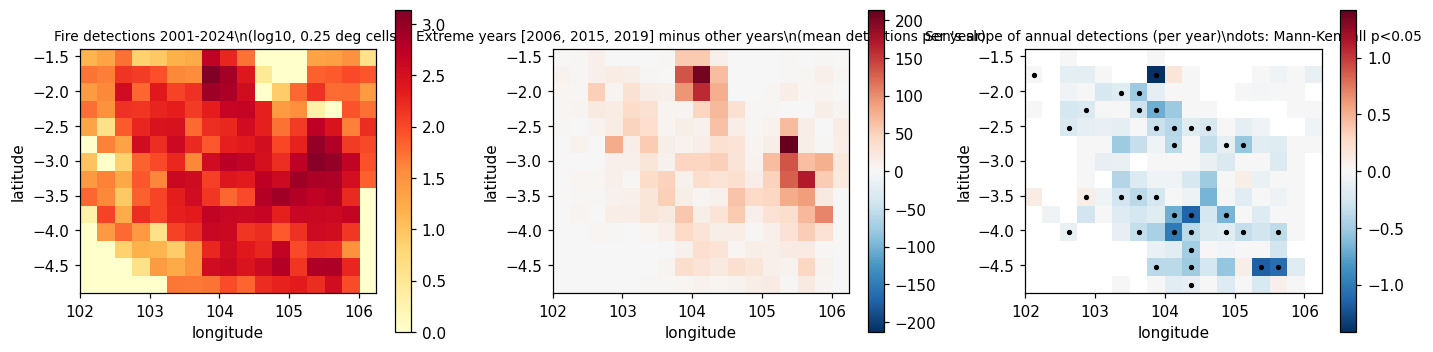

In [20]:
# 19. WHERE? Spatial fire-activity maps from FIRMS (no new data needed). Grid = 0.25 degree cells inside the study box.
# Fire counts here use the same filtered detections `f` as cell 8 (Terra MODIS, confidence >= CONF_MIN, type 0).
lon_e = np.arange(BBOX[0], BBOX[2] + 0.25, 0.25)
lat_e = np.arange(BBOX[1], BBOX[3] + 0.25, 0.25)
YEARS_ALL = list(range(2001, 2025))

ann = np.stack([np.histogram2d(f.loc[f.acq_date.dt.year == y, "latitude"], f.loc[f.acq_date.dt.year == y, "longitude"],
                               bins=[lat_e, lon_e])[0] for y in YEARS_ALL])      # shape: years x lat x lon
total = ann.sum(axis=0)
yearly = pd.Series(ann.sum(axis=(1, 2)), index=YEARS_ALL)
EXTREME = yearly.sort_values(ascending=False).head(3).index.tolist()             # data-driven: the 3 years with most detections
is_ext = np.array([y in EXTREME for y in YEARS_ALL])
print("Extreme years (most detections):", sorted(EXTREME), "| share of all detections:", f"{yearly[EXTREME].sum() / yearly.sum():.0%}")
flat = np.sort(total.ravel())[::-1]
print(f"Top 10% of cells hold {flat[:max(1, int(0.1 * len(flat)))].sum() / flat.sum():.0%} of detections ({len(flat)} cells)")

# Per-cell Mann-Kendall + Sen's slope on annual counts (cells with enough detections only)
MIN_TOTAL = 50
nlat, nlon = total.shape
slope, pval, tested = np.full(total.shape, np.nan), np.full(total.shape, np.nan), np.zeros(total.shape, bool)
for i in range(nlat):
    for j in range(nlon):
        x = ann[:, i, j]
        if total[i, j] >= MIN_TOTAL and np.count_nonzero(x) >= 8:
            _, _, z, p = mann_kendall(x)
            slope[i, j] = stats.theilslopes(x, np.array(YEARS_ALL, float))[0]
            pval[i, j], tested[i, j] = p, True
sig = tested & (pval < 0.05)
print(f"Cells tested: {int(tested.sum())} | significant at p<0.05: {int(sig.sum())} "
      f"(about {0.05 * tested.sum():.0f} would be expected by chance alone) | "
      f"increasing: {int((sig & (slope > 0)).sum())}, decreasing: {int((sig & (slope < 0)).sum())}")

diff = ann[is_ext].mean(axis=0) - ann[~is_ext].mean(axis=0)
ext_ = [lon_e[0], lon_e[-1], lat_e[0], lat_e[-1]]
fig, axs = plt.subplots(1, 3, figsize=(13, 4.2))
im0 = axs[0].imshow(np.log10(1 + total), origin="lower", extent=ext_, cmap="YlOrRd", aspect="equal")
axs[0].set_title("Fire detections 2001-2024\\n(log10, 0.25 deg cells)", fontsize=9); plt.colorbar(im0, ax=axs[0], shrink=0.75)
v = np.nanmax(np.abs(diff))
im1 = axs[1].imshow(diff, origin="lower", extent=ext_, cmap="RdBu_r", vmin=-v, vmax=v, aspect="equal")
axs[1].set_title(f"Extreme years {sorted(EXTREME)} minus other years\\n(mean detections per year)", fontsize=9); plt.colorbar(im1, ax=axs[1], shrink=0.75)
sl = np.ma.masked_invalid(slope); vs = np.nanmax(np.abs(slope)) if tested.any() else 1
im2 = axs[2].imshow(sl, origin="lower", extent=ext_, cmap="RdBu_r", vmin=-vs, vmax=vs, aspect="equal")
yy, xx = np.where(sig)
axs[2].scatter(lon_e[xx] + 0.125, lat_e[yy] + 0.125, s=6, c="k")
axs[2].set_title("Sen's slope of annual detections (per year)\\ndots: Mann-Kendall p<0.05", fontsize=9); plt.colorbar(im2, ax=axs[2], shrink=0.75)
for a in axs:
    a.set_xlabel("longitude"); a.set_ylabel("latitude")
plt.tight_layout(); plt.savefig("fig_fire_maps.png"); plt.show()


Satellite: Terra | years: 2001 - 2024
Extreme years (most detections): [2006, 2015, 2019] | share of all detections: 42%
Top 10% of cells hold 37% of detections (238 cells)
Cells tested: 155 | p<0.05 uncorrected: 35 (about 8 expected by chance) | after FDR correction: 11 | of the uncorrected: increasing 1, decreasing 33
Caution: neighbouring cells are spatially correlated, so these counts overstate how many independent trends exist.


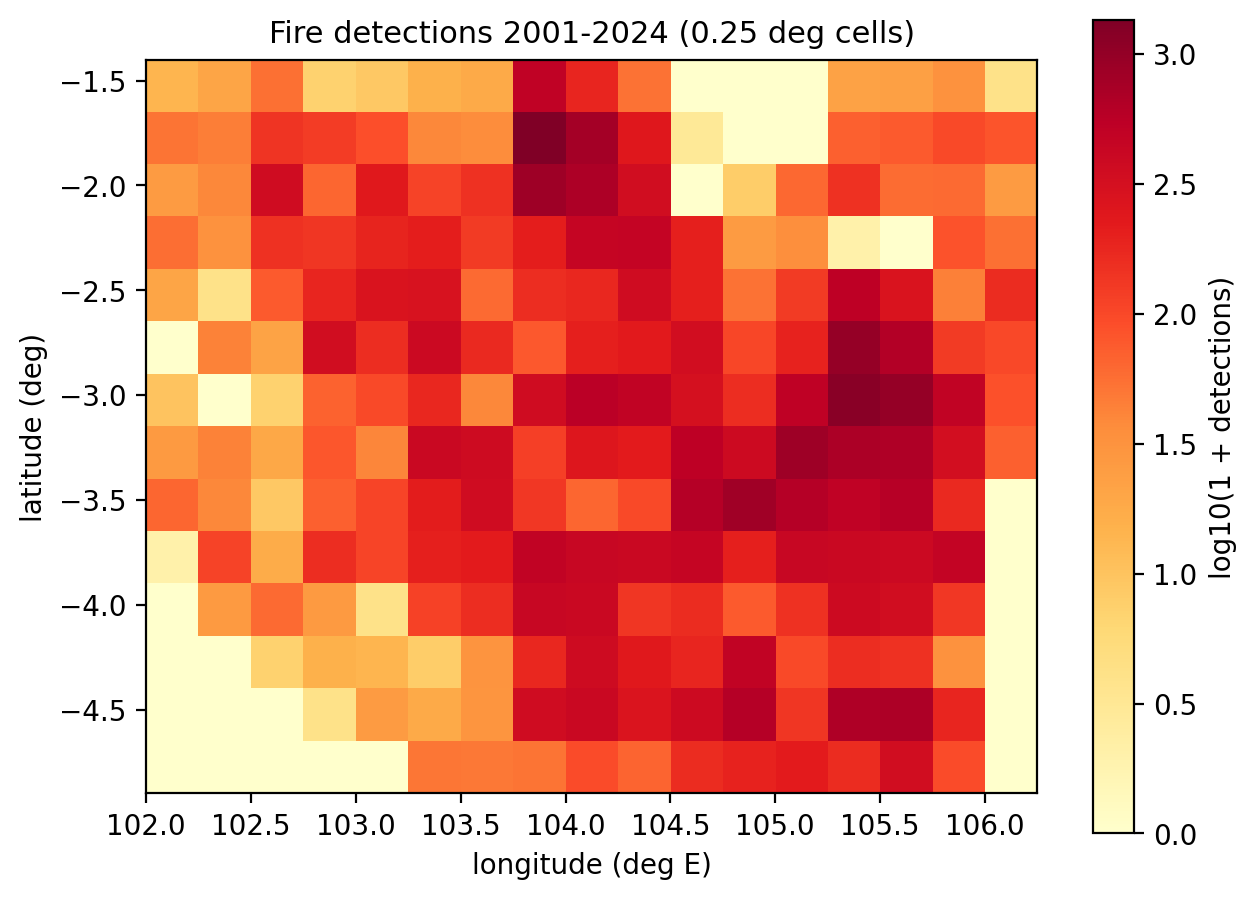

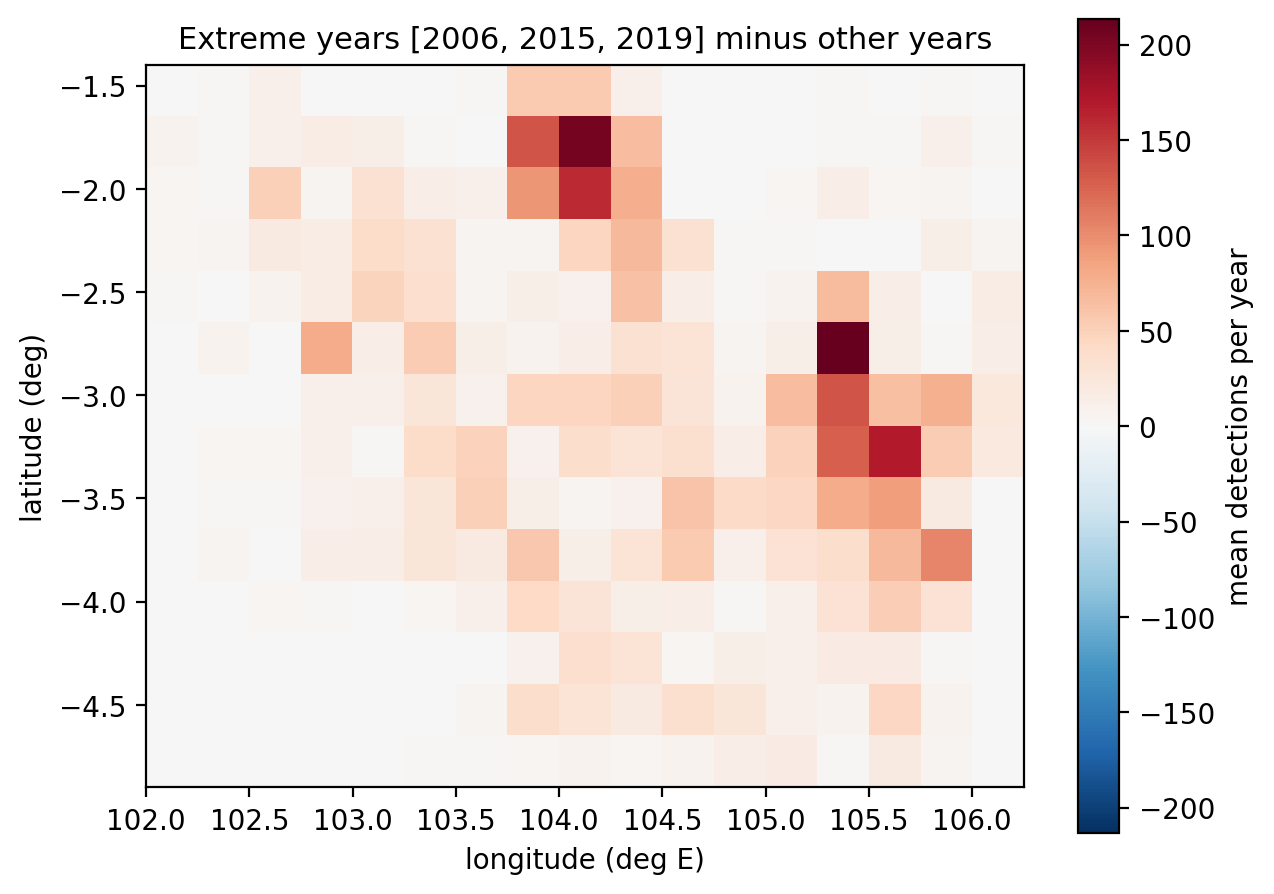

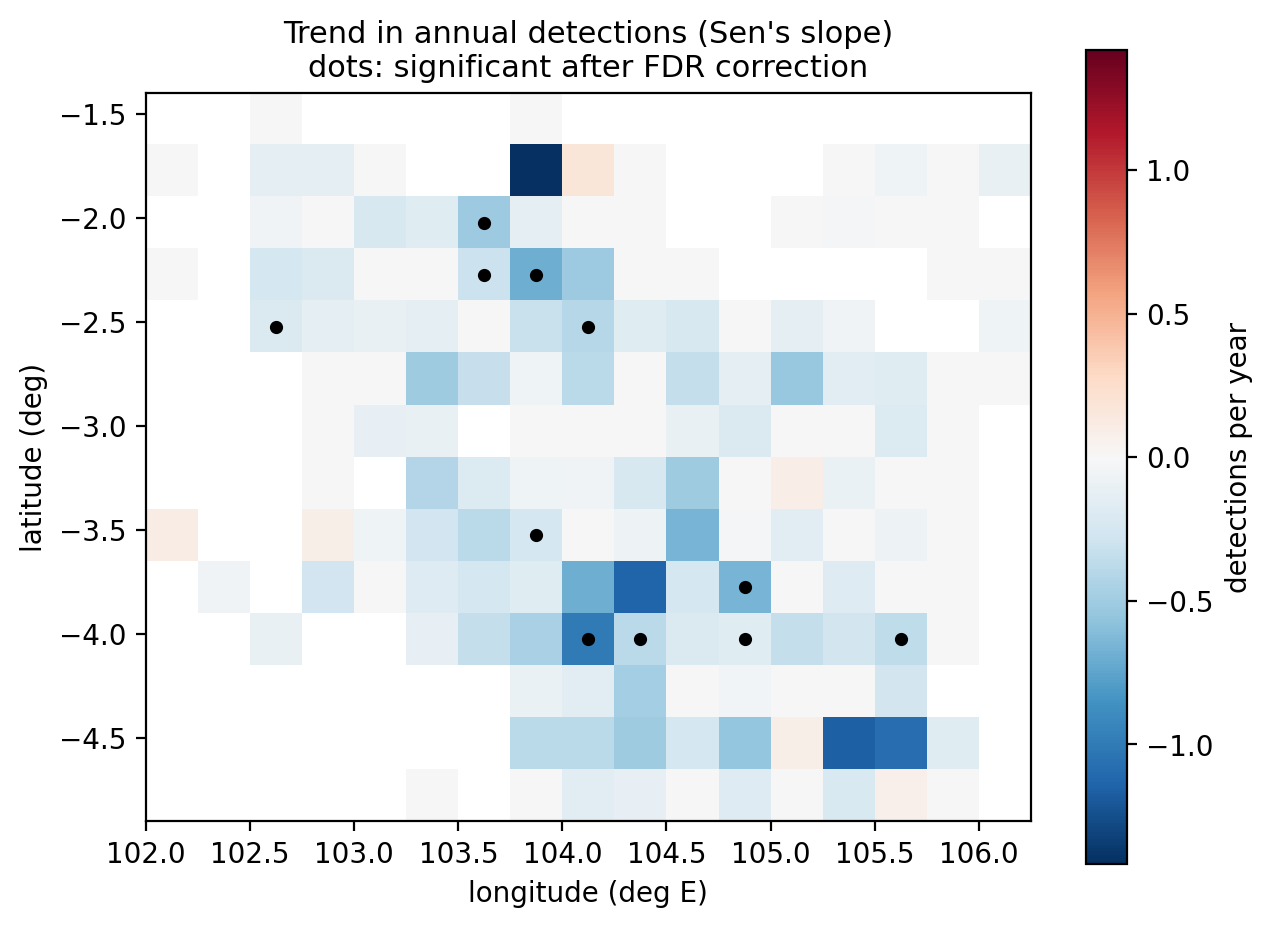

In [21]:
# 19. WHERE? Spatial fire-activity maps from FIRMS (no new data needed). Grid = 0.25 degree cells inside the study box.
# Fire counts here use the same filtered detections `f` as cell 8 (Terra MODIS, confidence >= CONF_MIN, type 0).
lon_e = np.arange(BBOX[0], BBOX[2] + 0.25, 0.25)
lat_e = np.arange(BBOX[1], BBOX[3] + 0.25, 0.25)
YEARS_ALL = list(range(2003 if SATELLITE == "Aqua" else 2001, 2025))      # Aqua starts mid-2002

ann = np.stack([np.histogram2d(f.loc[f.acq_date.dt.year == y, "latitude"], f.loc[f.acq_date.dt.year == y, "longitude"],
                               bins=[lat_e, lon_e])[0] for y in YEARS_ALL])      # shape: years x lat x lon
total = ann.sum(axis=0)
yearly = pd.Series(ann.sum(axis=(1, 2)), index=YEARS_ALL)
EXTREME = yearly.sort_values(ascending=False).head(3).index.tolist()             # data-driven: the 3 years with most detections
is_ext = np.array([y in EXTREME for y in YEARS_ALL])
print("Satellite:", SATELLITE, "| years:", YEARS_ALL[0], "-", YEARS_ALL[-1])
print("Extreme years (most detections):", sorted(EXTREME), "| share of all detections:", f"{yearly[EXTREME].sum() / yearly.sum():.0%}")
flat = np.sort(total.ravel())[::-1]
print(f"Top 10% of cells hold {flat[:max(1, int(0.1 * len(flat)))].sum() / flat.sum():.0%} of detections ({len(flat)} cells)")

# Per-cell Mann-Kendall + Sen's slope on annual counts (cells with enough detections only)
MIN_TOTAL = 50
nlat, nlon = total.shape
slope, pval, tested = np.full(total.shape, np.nan), np.full(total.shape, np.nan), np.zeros(total.shape, bool)
for i in range(nlat):
    for j in range(nlon):
        x = ann[:, i, j]
        if total[i, j] >= MIN_TOTAL and np.count_nonzero(x) >= 8:
            _, _, z, p = mann_kendall(x)
            slope[i, j] = stats.theilslopes(x, np.array(YEARS_ALL, float))[0]
            pval[i, j], tested[i, j] = p, True
sig = tested & (pval < 0.05)

# Benjamini-Hochberg false-discovery-rate control (many cells are tested at once)
pv = pval[tested]; m_ = len(pv)
fdr_sig = np.zeros(total.shape, bool)
if m_:
    order = np.argsort(pv)
    q = np.minimum.accumulate((pv[order] * m_ / np.arange(1, m_ + 1))[::-1])[::-1]
    qv = np.empty(m_); qv[order] = np.minimum(q, 1)
    fdr_sig[tested] = qv < 0.05
print(f"Cells tested: {int(tested.sum())} | p<0.05 uncorrected: {int(sig.sum())} (about {0.05 * tested.sum():.0f} expected by chance) | "
      f"after FDR correction: {int(fdr_sig.sum())} | of the uncorrected: increasing {int((sig & (slope > 0)).sum())}, decreasing {int((sig & (slope < 0)).sum())}")
print("Caution: neighbouring cells are spatially correlated, so these counts overstate how many independent trends exist.")

diff = ann[is_ext].mean(axis=0) - ann[~is_ext].mean(axis=0)
ext_ = [lon_e[0], lon_e[-1], lat_e[0], lat_e[-1]]

def one_map(data, title, fname, cmap, label, sym=False, dots=None):
    fig, ax = plt.subplots(figsize=(6.5, 5.4), dpi=200)
    kw = {}
    if sym:
        v = np.nanmax(np.abs(data)) if np.isfinite(data).any() else 1
        kw = dict(vmin=-v, vmax=v)
    im = ax.imshow(np.ma.masked_invalid(data), origin="lower", extent=ext_, cmap=cmap, aspect="equal", **kw)
    if dots is not None and dots.any():
        yy, xx = np.where(dots)
        ax.scatter(lon_e[xx] + 0.125, lat_e[yy] + 0.125, s=14, c="k")
    ax.set_title(title, fontsize=11); ax.set_xlabel("longitude (deg E)"); ax.set_ylabel("latitude (deg)")
    plt.colorbar(im, ax=ax, shrink=0.8, label=label)
    plt.tight_layout(); plt.savefig(fname, dpi=200); plt.show()

one_map(np.log10(1 + total), f"Fire detections {YEARS_ALL[0]}-{YEARS_ALL[-1]} (0.25 deg cells)", "fig_fire_density.png",
        "YlOrRd", "log10(1 + detections)")
one_map(diff, f"Extreme years {sorted(EXTREME)} minus other years", "fig_fire_extreme_diff.png",
        "RdBu_r", "mean detections per year", sym=True)
one_map(slope, "Trend in annual detections (Sen's slope)\ndots: significant after FDR correction", "fig_fire_trend.png",
        "RdBu_r", "detections per year", sym=True, dots=fdr_sig)


Boundary file: /kaggle/input/datasets/hendrikharyanto/map-adm1/geoBoundaries-IDN-ADM1_simplified.geojson
Matched: ['South Sumatra']
Satellite Terra: 33724 of 45972 detections in the study box are inside the province (73%)


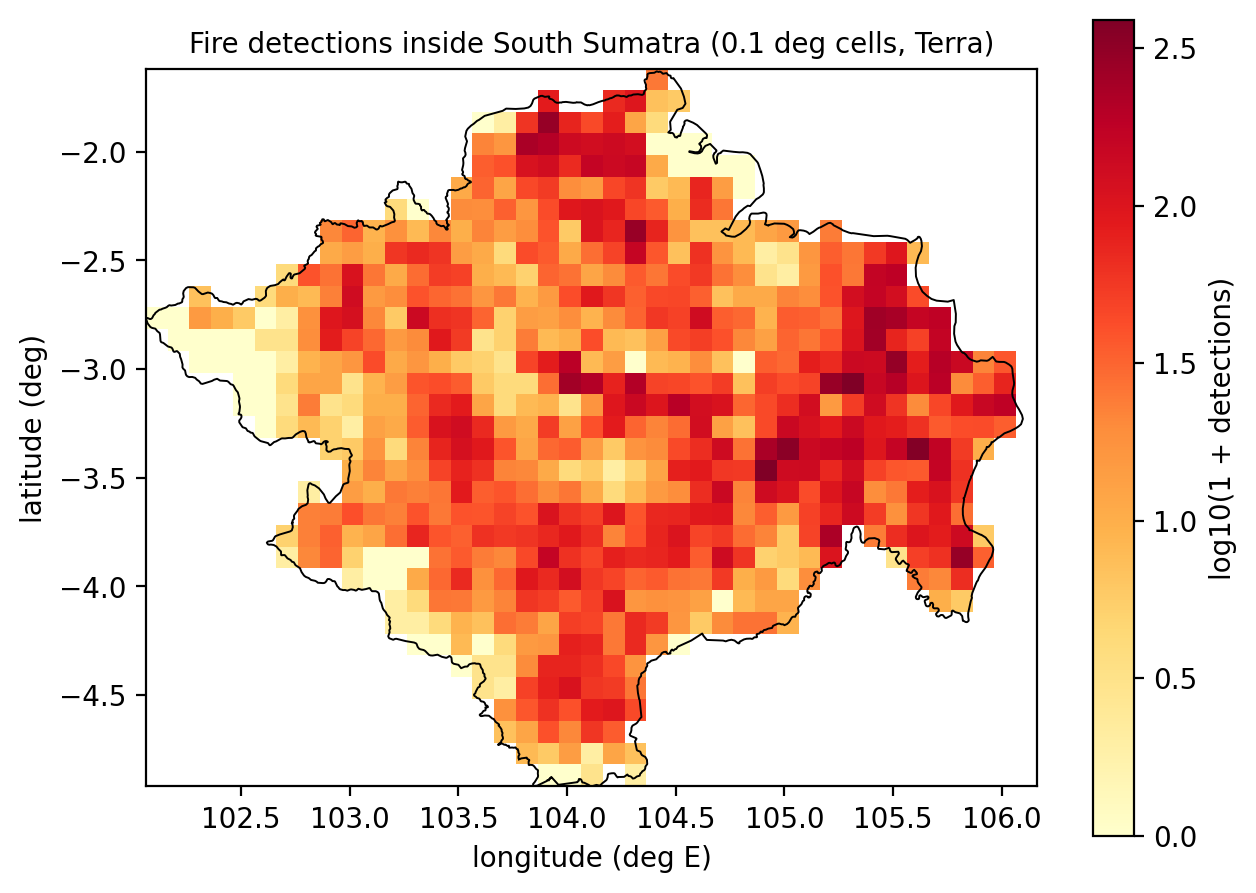

[province only, Terra] Spearman rain_AugOct vs fires_AugOct_prov: rho=-0.91, p=7.47e-10, n=24
[province only, Terra] Spearman longest_dry vs fires_AugOct_prov: rho=0.77, p=8.82e-06, n=24


In [22]:
# 20. Real province outline: draw it, save region.geojson, and keep only detections INSIDE South Sumatra (robustness check).
# Needs the geoBoundaries Indonesia ADM1 GeoJSON added to the notebook as a dataset (any file name containing "ADM1").
import json, re
from matplotlib.path import Path as MPath

BND = None
for root, _, names in os.walk("/kaggle/input"):
    for n in names:
        if n.lower().endswith(".geojson") and "ADM1" in n.upper():
            BND = os.path.join(root, n)
print("Boundary file:", BND)
gj = json.load(open(BND))
feats = gj["features"]
pat = re.compile(r"(sumat.*(selatan|south))|(south.*sumat)", re.I)
sel = [ft for ft in feats if pat.search(str(ft["properties"].get("shapeName", "")))]
if not sel:
    print("No match. Province names in the file:", [ft["properties"].get("shapeName") for ft in feats])
    raise ValueError("South Sumatra not found: pick the right name from the list above and edit the regex `pat`.")
print("Matched:", [ft["properties"].get("shapeName") for ft in sel])
json.dump({"type": "FeatureCollection", "features": sel}, open("region.geojson", "w"))   # = config/region.geojson in the repo

polys = []
for ft in sel:
    g = ft["geometry"]
    polys += [g["coordinates"]] if g["type"] == "Polygon" else list(g["coordinates"])
polys = [[np.array(r)[:, :2] for r in poly] for poly in polys]         # [outer, hole, hole...] per polygon

def inside(pts):
    ok = np.zeros(len(pts), bool)
    for poly in polys:
        m = MPath(poly[0]).contains_points(pts)
        for hole in poly[1:]:
            m &= ~MPath(hole).contains_points(pts)
        ok |= m
    return ok

f_prov = f[inside(np.column_stack([f.longitude.values, f.latitude.values]))]
print(f"Satellite {SATELLITE}: {len(f_prov)} of {len(f)} detections in the study box are inside the province ({len(f_prov) / len(f):.0%})")

# Finer (0.1 deg) density map, cells outside the province left blank so the province shape appears
allxy = np.vstack([r for poly in polys for r in poly[:1]])
x0, x1, y0, y1 = allxy[:, 0].min(), allxy[:, 0].max(), allxy[:, 1].min(), allxy[:, 1].max()
xe, ye = np.arange(x0, x1 + 0.1, 0.1), np.arange(y0, y1 + 0.1, 0.1)
H = np.histogram2d(f_prov.latitude, f_prov.longitude, bins=[ye, xe])[0]
cx, cy = np.meshgrid((xe[:-1] + xe[1:]) / 2, (ye[:-1] + ye[1:]) / 2)
inside_cell = inside(np.column_stack([cx.ravel(), cy.ravel()])).reshape(H.shape)
Hm = np.where(inside_cell, np.log10(1 + H), np.nan)
fig, ax = plt.subplots(figsize=(6.5, 5.4), dpi=200)
im = ax.imshow(np.ma.masked_invalid(Hm), origin="lower", extent=[xe[0], xe[-1], ye[0], ye[-1]], cmap="YlOrRd", aspect="equal")
for poly in polys:
    for ring in poly:
        ax.plot(ring[:, 0], ring[:, 1], color="k", lw=0.7)
ax.set_title(f"Fire detections inside South Sumatra (0.1 deg cells, {SATELLITE})", fontsize=10)
ax.set_xlabel("longitude (deg E)"); ax.set_ylabel("latitude (deg)"); plt.colorbar(im, ax=ax, shrink=0.8, label="log10(1 + detections)")
plt.tight_layout(); plt.savefig("fig_fire_density_province.png", dpi=200); plt.show()

# Robustness: rainfall vs fire link using ONLY detections inside the province
fp = f_prov[f_prov.acq_date.dt.month.isin([8, 9, 10])]
fp = fp.groupby(fp.acq_date.dt.year).size().rename("fires_AugOct_prov")
jp = pd.concat([ao, longest.rename("longest_dry"), fp], axis=1).dropna()
for a_, b_ in [("rain_AugOct", "fires_AugOct_prov"), ("longest_dry", "fires_AugOct_prov")]:
    r_, p_ = stats.spearmanr(jp[a_], jp[b_]); print(f"[province only, {SATELLITE}] Spearman {a_} vs {b_}: rho={r_:.2f}, p={p_:.3g}, n={len(jp)}")


In [23]:
# 21. Climate drivers: can the Indian Ocean Dipole (and ENSO, if added) give EARLIER warning? (walk-forward, same alarm rule as cells 16 and 18)
# DMI = NOAA PSL HadISST1.1 Dipole Mode Index (NOT NASA data; cite it as an additional source). Values pasted from the PSL file; -9999 = missing.
# Lag rule: for a prediction on day t we only use months up to t-2, because recent DMI values can be revised for up to two months.
DMI_TEXT = """
1999    -0.130    -0.038     0.102    -0.001    -0.186    -0.146     0.111     0.023    -0.049    -0.189    -0.116    -0.148
2000    -0.125    -0.009     0.141     0.141     0.113    -0.022     0.077     0.131    -0.096    -0.142    -0.306    -0.248
2001    -0.431    -0.016    -0.010     0.136     0.137     0.127    -0.140    -0.301    -0.223    -0.451    -0.245    -0.051
2002    -0.142    -0.098     0.008    -0.352    -0.329    -0.189    -0.261    -0.208     0.286     0.405     0.096    -0.158
2003    -0.239     0.017    -0.039    -0.099    -0.164     0.139     0.131     0.108    -0.060    -0.243    -0.159     0.189
2004     0.044     0.114     0.077    -0.079    -0.565    -0.384    -0.301    -0.133    -0.106    -0.004    -0.153    -0.132
2005    -0.124    -0.560    -0.433     0.084    -0.033    -0.176    -0.384    -0.345    -0.534    -0.436    -0.272    -0.300
2006    -0.135    -0.306    -0.226    -0.015    -0.208    -0.059     0.040     0.229     0.428     0.577     0.501     0.172
2007     0.225     0.150     0.115     0.100     0.270     0.031     0.045     0.237     0.235     0.068    -0.023    -0.227
2008     0.115    -0.072     0.097    -0.153     0.179     0.215     0.246     0.124     0.086     0.029    -0.128    -0.053
2009     0.031     0.163     0.100     0.126     0.257     0.100    -0.192    -0.104    -0.103    -0.013    -0.067     0.160
2010     0.294     0.023     0.458     0.370    -0.029    -0.140    -0.001    -0.061    -0.267    -0.437    -0.495    -0.212
2011     0.191     0.241     0.367     0.154    -0.089     0.055     0.223     0.344     0.202     0.356     0.336    -0.128
2012     0.046    -0.078     0.026    -0.271    -0.370     0.000     0.546     0.652     0.453     0.110    -0.099     0.267
2013    -0.065     0.189     0.083    -0.297    -0.506    -0.497    -0.181    -0.194    -0.310    -0.168     0.199     0.141
2014    -0.101    -0.089    -0.151    -0.058    -0.092    -0.028    -0.363    -0.372    -0.145     0.141     0.009     0.046
2015    -0.100    -0.345    -0.241    -0.008     0.240     0.296     0.225     0.568     0.294     0.482     0.347     0.272
2016     0.265    -0.110    -0.008     0.146    -0.113    -0.443    -0.757    -0.443    -0.437    -0.371    -0.382    -0.310
2017    -0.086     0.101     0.357     0.498     0.536     0.424     0.520     0.349     0.035     0.015     0.289     0.110
2018    -0.200     0.216    -0.120    -0.083     0.122     0.155     0.053     0.121     0.604     0.684     0.500     0.309
2019     0.387     0.416     0.225     0.258     0.540     0.605     0.597     0.436     0.892     0.964     0.835     0.243
2020     0.173     0.054     0.019    -0.011     0.298     0.455     0.319    -0.183    -0.189     0.074     0.020     0.031
2021     0.051     0.243     0.267     0.250     0.009    -0.002    -0.229    -0.099    -0.058    -0.091     0.069    -0.120
2022    -0.056    -0.082    -0.093    -0.068    -0.122    -0.335    -0.195    -0.246    -0.322    -0.691    -0.269    -0.091
2023     0.110     0.157     0.414     0.560     0.443     0.665     0.498     0.826     0.946     0.804     0.920     0.852
2024     0.765     0.327     0.421     0.440     0.298     0.197     0.033     0.267     0.115    -0.196    -0.382    -0.331
2025    -0.196     0.017     0.058     0.149     0.107    -0.014    -0.072    -0.420    -0.467    -0.448    -0.256    -0.017
2026     0.123     0.529     0.285     0.279     0.146 -9999.000 -9999.000 -9999.000 -9999.000 -9999.000 -9999.000 -9999.000
"""
# Optional ENSO: paste Nino 3.4 monthly data below from the NOAA CPC file (ersst5.nino.mth.91-20.ascii, last column = Nino 3.4 anomaly)
# or from a PSL "year + 12 monthly values" file. Leave empty to test the IOD only.
ENSO_TEXT = """
1999   1   23.79   -0.78   24.41   -1.25   26.64   -1.68   24.86   -1.69
1999   2   25.56   -0.54   25.52   -0.88   26.56   -1.64   25.43   -1.32
1999   3   26.45   -0.04   26.68   -0.52   26.98   -1.35   26.33   -0.95
1999   4   24.64   -0.90   26.71   -0.87   27.41   -1.21   26.70   -1.11
1999   5   23.73   -0.69   26.45   -0.81   27.89   -1.03   26.79   -1.15
1999   6   22.36   -0.76   25.72   -0.90   27.96   -1.01   26.53   -1.19
1999   7   21.73   -0.23   25.05   -0.76   27.75   -1.14   26.13   -1.17
1999   8   20.89   -0.11   24.28   -0.84   27.69   -1.10   25.63   -1.22
1999   9   19.67   -1.05   23.79   -1.11   27.79   -0.97   25.63   -1.09
1999  10   20.15   -0.86   23.60   -1.38   27.79   -0.97   25.48   -1.23
1999  11   20.43   -1.23   23.60   -1.50   27.42   -1.27   25.12   -1.58
1999  12   22.17   -0.64   23.68   -1.55   27.18   -1.36   24.86   -1.74
2000   1   23.81   -0.76   24.00   -1.66   26.99   -1.33   24.78   -1.77
2000   2   25.48   -0.62   25.27   -1.14   26.73   -1.47   25.21   -1.55
2000   3   26.02   -0.47   26.70   -0.50   26.89   -1.43   26.30   -0.98
2000   4   25.50   -0.04   27.41   -0.17   27.20   -1.43   26.95   -0.87
2000   5   24.02   -0.40   26.88   -0.37   27.63   -1.29   27.07   -0.86
2000   6   22.75   -0.38   26.03   -0.59   28.06   -0.91   26.94   -0.79
2000   7   21.68   -0.28   25.18   -0.62   28.17   -0.73   26.63   -0.67
2000   8   20.44   -0.57   24.64   -0.48   28.16   -0.62   26.37   -0.49
2000   9   20.50   -0.23   24.59   -0.32   28.27   -0.49   26.20   -0.52
2000  10   20.74   -0.27   24.48   -0.50   28.11   -0.65   26.02   -0.70
2000  11   20.46   -1.19   24.40   -0.70   27.92   -0.77   25.92   -0.79
2000  12   21.85   -0.96   24.57   -0.66   27.59   -0.95   25.68   -0.92
2001   1   23.94   -0.63   25.24   -0.42   27.43   -0.89   25.81   -0.73
2001   2   25.62   -0.48   26.12   -0.28   27.37   -0.82   26.12   -0.63
2001   3   26.66    0.17   27.20   -0.01   27.61   -0.71   26.80   -0.48
2001   4   25.72    0.18   27.46   -0.12   28.04   -0.59   27.33   -0.49
2001   5   23.71   -0.71   27.11   -0.14   28.53   -0.39   27.60   -0.34
2001   6   22.28   -0.85   26.34   -0.28   28.79   -0.17   27.54   -0.19
2001   7   21.38   -0.58   25.53   -0.27   28.98    0.09   27.25   -0.04
2001   8   20.16   -0.84   24.90   -0.22   28.84    0.05   26.80   -0.05
2001   9   19.60   -1.13   24.31   -0.59   28.97    0.21   26.52   -0.20
2001  10   19.88   -1.13   24.55   -0.43   28.95    0.19   26.57   -0.14
2001  11   20.77   -0.89   24.42   -0.68   28.78    0.08   26.33   -0.37
2001  12   21.79   -1.02   24.61   -0.62   28.66    0.12   26.19   -0.41
2002   1   23.79   -0.78   25.17   -0.49   28.72    0.40   26.39   -0.15
2002   2   26.03   -0.07   26.16   -0.24   28.66    0.46   26.71   -0.04
2002   3   27.25    0.77   27.35    0.14   28.57    0.25   27.29    0.01
2002   4   26.35    0.82   27.58    0.00   29.03    0.41   27.84    0.02
2002   5   25.04    0.63   27.51    0.26   29.52    0.60   28.24    0.31
2002   6   23.51    0.38   27.19    0.57   29.61    0.64   28.44    0.72
2002   7   21.72   -0.23   26.19    0.39   29.52    0.63   28.03    0.74
2002   8   20.74   -0.26   25.63    0.51   29.43    0.64   27.72    0.87
2002   9   20.93    0.20   25.76    0.86   29.37    0.61   27.81    1.09
2002  10   21.39    0.37   25.97    0.99   29.41    0.65   27.96    1.25
2002  11   22.63    0.97   26.40    1.30   29.55    0.85   28.17    1.47
2002  12   23.91    1.10   26.44    1.21   29.38    0.84   27.97    1.37
2003   1   24.69    0.13   26.23    0.57   28.89    0.57   27.15    0.60
2003   2   25.98   -0.12   26.84    0.44   28.88    0.69   27.39    0.64
2003   3   26.42   -0.07   27.39    0.19   28.92    0.60   27.65    0.36
2003   4   24.98   -0.56   27.14   -0.44   28.96    0.33   27.68   -0.14
2003   5   22.77   -1.65   26.29   -0.96   28.86   -0.05   27.32   -0.61
2003   6   21.77   -1.35   26.03   -0.59   29.07    0.10   27.44   -0.29
2003   7   20.95   -1.01   25.92    0.12   29.08    0.19   27.50    0.21
2003   8   21.02    0.01   25.38    0.26   28.98    0.19   27.11    0.26
2003   9   20.28   -0.45   25.05    0.15   28.94    0.18   26.99    0.27
2003  10   21.25    0.23   25.38    0.40   29.12    0.36   27.14    0.42
2003  11   21.94    0.28   25.75    0.64   29.07    0.37   27.04    0.33
2003  12   23.03    0.22   26.00    0.77   28.97    0.43   27.03    0.43
2004   1   24.36   -0.21   26.08    0.42   28.75    0.43   26.81    0.27
2004   2   26.03   -0.07   26.70    0.30   28.57    0.38   26.98    0.23
2004   3   25.75   -0.74   27.34    0.13   28.42    0.10   27.40    0.12
2004   4   24.96   -0.57   27.52   -0.07   28.71    0.09   27.89    0.07
2004   5   22.82   -1.59   26.80   -0.45   29.02    0.11   28.00    0.06
2004   6   22.05   -1.07   26.35   -0.26   29.19    0.22   27.86    0.13
2004   7   21.18   -0.78   25.78   -0.02   29.32    0.42   27.78    0.49
2004   8   20.26   -0.75   25.36    0.24   29.34    0.55   27.62    0.76
2004   9   20.46   -0.27   25.35    0.45   29.45    0.69   27.53    0.81
2004  10   21.16    0.15   25.52    0.54   29.46    0.70   27.44    0.73
2004  11   22.37    0.72   25.73    0.63   29.45    0.76   27.36    0.66
2004  12   23.18    0.36   25.91    0.69   29.41    0.87   27.34    0.74
2005   1   24.54   -0.02   25.98    0.32   29.20    0.88   27.21    0.66
2005   2   25.16   -0.94   26.31   -0.09   28.87    0.67   27.11    0.36
2005   3   25.03   -1.46   27.14   -0.07   28.93    0.61   27.73    0.45
2005   4   25.12   -0.42   27.53   -0.05   29.05    0.42   28.08    0.26
2005   5   24.04   -0.38   27.41    0.16   29.21    0.29   28.24    0.30
2005   6   22.35   -0.77   26.68    0.06   29.14    0.17   27.77    0.04
2005   7   21.61   -0.35   25.91    0.10   28.79   -0.11   27.06   -0.23
2005   8   20.61   -0.40   25.30    0.18   28.73   -0.06   26.80   -0.05
2005   9   19.99   -0.74   24.82   -0.08   28.79    0.03   26.68   -0.04
2005  10   19.75   -1.27   24.64   -0.34   28.85    0.09   26.65   -0.06
2005  11   20.23   -1.43   23.97   -1.13   28.55   -0.14   26.11   -0.59
2005  12   21.89   -0.92   24.00   -1.22   28.28   -0.26   25.68   -0.92
2006   1   24.19   -0.37   24.85   -0.81   27.82   -0.50   25.63   -0.91
2006   2   26.32    0.22   26.06   -0.35   27.52   -0.67   26.08   -0.67
2006   3   26.20   -0.29   26.65   -0.55   27.73   -0.59   26.57   -0.71
2006   4   24.04   -1.50   27.16   -0.42   28.29   -0.34   27.50   -0.32
2006   5   23.86   -0.56   27.17   -0.08   28.86   -0.06   27.85   -0.09
2006   6   22.91   -0.21   26.61   -0.01   29.03    0.06   27.73    0.00
2006   7   22.16    0.20   25.82    0.01   29.10    0.20   27.30    0.01
2006   8   21.71    0.70   25.51    0.39   29.21    0.42   27.16    0.31
2006   9   21.70    0.97   25.73    0.83   29.40    0.63   27.32    0.60
2006  10   22.07    1.05   25.86    0.88   29.45    0.69   27.41    0.70
2006  11   22.45    0.79   26.10    0.99   29.62    0.92   27.69    0.99
2006  12   23.52    0.71   26.37    1.14   29.46    0.92   27.74    1.14
2007   1   25.23    0.66   26.53    0.87   28.97    0.65   27.24    0.70
2007   2   26.21    0.11   26.49    0.08   28.66    0.46   26.88    0.13
2007   3   25.84   -0.64   26.80   -0.40   28.66    0.34   27.10   -0.18
2007   4   24.31   -1.22   26.95   -0.63   28.73    0.10   27.50   -0.32
2007   5   22.63   -1.79   26.37   -0.88   28.84   -0.08   27.46   -0.47
2007   6   21.52   -1.61   25.90   -0.72   28.90   -0.07   27.37   -0.35
2007   7   20.98   -0.98   24.85   -0.95   28.68   -0.22   26.71   -0.59
2007   8   19.81   -1.20   23.94   -1.18   28.48   -0.31   26.14   -0.72
2007   9   19.75   -0.97   23.63   -1.27   28.11   -0.65   25.61   -1.11
2007  10   19.50   -1.52   23.55   -1.43   27.91   -0.85   25.32   -1.39
2007  11   19.92   -1.73   23.48   -1.62   27.61   -1.09   25.17   -1.54
2007  12   21.15   -1.66   23.57   -1.66   27.42   -1.12   25.01   -1.58
2008   1   24.08   -0.48   24.19   -1.46   26.87   -1.45   24.86   -1.68
2008   2   26.32    0.22   25.16   -1.24   26.62   -1.58   25.08   -1.67
2008   3   26.88    0.39   26.45   -0.75   26.97   -1.35   26.07   -1.21
2008   4   25.94    0.41   27.12   -0.46   27.46   -1.16   26.83   -0.99
2008   5   24.95    0.54   27.00   -0.25   27.81   -1.11   27.09   -0.84
2008   6   23.68    0.55   26.46   -0.16   27.96   -1.01   27.04   -0.68
2008   7   22.95    0.99   26.08    0.28   28.07   -0.83   26.99   -0.30
2008   8   22.40    1.40   25.62    0.50   28.04   -0.75   26.72   -0.13
2008   9   21.75    1.02   25.20    0.30   28.08   -0.68   26.47   -0.25
2008  10   21.37    0.35   25.07    0.09   28.17   -0.59   26.37   -0.35
2008  11   21.38   -0.28   24.98   -0.12   27.98   -0.72   26.25   -0.46
2008  12   22.36   -0.45   24.66   -0.56   27.73   -0.81   25.74   -0.86
2009   1   24.40   -0.17   25.15   -0.51   27.37   -0.95   25.66   -0.89
2009   2   25.42   -0.68   25.84   -0.57   27.35   -0.85   25.96   -0.79
2009   3   25.67   -0.81   26.49   -0.71   27.74   -0.58   26.59   -0.69
2009   4   25.94    0.41   27.41   -0.17   28.37   -0.26   27.47   -0.35
2009   5   24.76    0.34   27.54    0.29   28.90   -0.01   27.99    0.06
2009   6   23.78    0.65   27.18    0.56   29.14    0.18   28.04    0.31
2009   7   22.71    0.75   26.49    0.69   29.19    0.29   27.78    0.48
2009   8   21.85    0.84   25.92    0.80   29.23    0.44   27.42    0.56
2009   9   21.23    0.51   25.69    0.78   29.33    0.57   27.40    0.68
2009  10   21.34    0.32   25.76    0.78   29.68    0.92   27.60    0.89
2009  11   21.99    0.33   26.18    1.08   29.82    1.12   28.16    1.46
2009  12   23.41    0.60   26.55    1.33   29.72    1.18   28.34    1.74
2010   1   24.85    0.28   26.73    1.07   29.44    1.12   28.07    1.52
2010   2   26.22    0.12   27.28    0.88   29.08    0.88   28.01    1.25
2010   3   26.56    0.07   27.76    0.55   29.07    0.75   28.18    0.90
2010   4   25.43   -0.11   27.85    0.27   29.13    0.50   28.20    0.38
2010   5   24.65    0.24   27.08   -0.17   29.01    0.10   27.71   -0.22
2010   6   23.14    0.01   25.91   -0.71   28.66   -0.31   27.04   -0.69
2010   7   20.93   -1.03   24.79   -1.01   28.10   -0.79   26.22   -1.07
2010   8   19.70   -1.31   23.97   -1.14   27.54   -1.25   25.47   -1.39
2010   9   19.50   -1.22   23.61   -1.29   27.32   -1.44   25.12   -1.60
2010  10   19.73   -1.28   23.50   -1.48   27.15   -1.61   25.03   -1.69
2010  11   20.34   -1.31   23.59   -1.52   27.11   -1.59   25.06   -1.64
2010  12   21.91   -0.90   23.73   -1.50   27.09   -1.45   25.00   -1.60
2011   1   24.08   -0.48   24.40   -1.26   26.92   -1.40   25.00   -1.54
2011   2   25.94   -0.16   25.63   -0.77   27.15   -1.05   25.64   -1.11
2011   3   25.61   -0.88   26.47   -0.73   27.51   -0.81   26.36   -0.93
2011   4   25.34   -0.19   27.25   -0.33   27.89   -0.74   27.05   -0.77
2011   5   24.53    0.11   26.96   -0.29   28.35   -0.57   27.41   -0.52
2011   6   23.42    0.30   26.50   -0.12   28.46   -0.51   27.35   -0.38
2011   7   22.06    0.10   25.61   -0.20   28.42   -0.48   26.87   -0.43
2011   8   20.79   -0.21   24.73   -0.39   28.16   -0.63   26.21   -0.65
2011   9   19.99   -0.74   24.29   -0.61   28.00   -0.76   25.92   -0.80
2011  10   20.24   -0.78   23.92   -1.06   27.86   -0.90   25.67   -1.05
2011  11   21.09   -0.57   23.98   -1.12   27.80   -0.90   25.52   -1.19
2011  12   22.13   -0.68   24.31   -0.92   27.53   -1.01   25.54   -1.06
2012   1   24.38   -0.18   25.09   -0.57   27.30   -1.02   25.67   -0.87
2012   2   26.46    0.36   26.22   -0.19   27.29   -0.91   26.08   -0.67
2012   3   26.65    0.16   27.02   -0.18   27.56   -0.77   26.67   -0.61
2012   4   26.44    0.90   27.56   -0.02   28.03   -0.59   27.32   -0.50
2012   5   25.29    0.87   27.34    0.09   28.40   -0.52   27.61   -0.32
2012   6   24.14    1.02   27.05    0.44   28.58   -0.39   27.75    0.02
2012   7   22.36    0.40   26.37    0.57   28.64   -0.26   27.54    0.25
2012   8   21.07    0.07   25.64    0.52   28.86    0.08   27.32    0.47
2012   9   20.79    0.06   25.24    0.34   28.97    0.21   27.10    0.38
2012  10   20.65   -0.37   25.00    0.02   29.07    0.31   26.98    0.26
2012  11   21.24   -0.41   25.08   -0.02   29.00    0.30   26.86    0.16
2012  12   21.96   -0.85   24.80   -0.42   28.60    0.06   26.34   -0.25
2013   1   23.89   -0.68   25.00   -0.66   28.24   -0.08   26.01   -0.53
2013   2   25.37   -0.73   25.84   -0.56   28.01   -0.19   26.24   -0.52
2013   3   25.81   -0.67   27.08   -0.12   27.95   -0.37   27.03   -0.25
2013   4   24.31   -1.23   27.22   -0.36   28.36   -0.27   27.57   -0.25
2013   5   22.83   -1.58   26.43   -0.82   28.69   -0.23   27.53   -0.40
2013   6   21.22   -1.91   25.73   -0.89   28.77   -0.20   27.30   -0.42
2013   7   20.36   -1.60   25.10   -0.70   28.66   -0.24   26.91   -0.39
2013   8   19.85   -1.16   24.47   -0.65   28.61   -0.18   26.47   -0.38
2013   9   19.95   -0.77   24.58   -0.33   28.65   -0.11   26.54   -0.18
2013  10   20.27   -0.75   24.79   -0.19   28.72   -0.04   26.52   -0.20
2013  11   21.09   -0.56   24.90   -0.20   28.74    0.04   26.56   -0.14
2013  12   22.37   -0.44   25.09   -0.13   28.48   -0.06   26.43   -0.17
2014   1   24.56   -0.01   25.23   -0.43   28.14   -0.18   26.05   -0.49
2014   2   25.49   -0.61   25.62   -0.79   28.27    0.07   26.14   -0.62
2014   3   26.17   -0.31   26.89   -0.32   28.60    0.28   27.00   -0.28
2014   4   25.51   -0.03   27.64    0.06   28.98    0.35   27.90    0.08
2014   5   25.48    1.06   27.64    0.38   29.45    0.53   28.25    0.32
2014   6   24.67    1.54   27.15    0.53   29.36    0.39   27.96    0.23
2014   7   22.94    0.98   26.12    0.31   29.04    0.14   27.23   -0.06
2014   8   21.90    0.89   25.30    0.18   29.04    0.25   26.82   -0.03
2014   9   21.52    0.80   25.27    0.37   29.16    0.39   27.01    0.29
2014  10   21.71    0.69   25.56    0.58   29.24    0.48   27.16    0.44
2014  11   22.45    0.80   25.88    0.77   29.43    0.73   27.46    0.75
2014  12   23.22    0.41   25.91    0.68   29.30    0.76   27.31    0.71
2015   1   24.41   -0.16   26.01    0.35   29.07    0.75   27.05    0.51
2015   2   25.57   -0.53   26.46    0.05   29.07    0.87   27.17    0.42
2015   3   26.57    0.09   27.30    0.10   29.22    0.90   27.75    0.47
2015   4   26.54    1.00   28.21    0.63   29.61    0.98   28.52    0.70
2015   5   25.96    1.55   28.20    0.94   29.85    0.94   28.85    0.92
2015   6   25.32    2.19   28.07    1.45   29.88    0.92   28.90    1.18
2015   7   24.50    2.54   27.66    1.85   29.78    0.88   28.75    1.46
2015   8   22.66    1.65   27.21    2.09   29.77    0.99   28.79    1.93
2015   9   23.01    2.28   27.40    2.50   29.82    1.06   28.93    2.21
2015  10   23.14    2.12   27.60    2.62   29.84    1.08   29.08    2.36
2015  11   23.93    2.28   27.95    2.84   30.13    1.44   29.42    2.72
2015  12   25.02    2.21   28.07    2.84   29.91    1.37   29.26    2.66
2016   1   26.36    1.79   28.25    2.59   29.54    1.22   29.11    2.57
2016   2   27.40    1.30   28.38    1.97   29.41    1.22   29.01    2.26
2016   3   27.83    1.35   28.74    1.53   29.39    1.07   28.90    1.62
2016   4   25.98    0.45   28.20    0.62   29.37    0.74   28.72    0.91
2016   5   24.90    0.49   27.23   -0.03   29.45    0.53   28.23    0.30
2016   6   23.77    0.64   26.48   -0.14   29.35    0.39   27.69   -0.03
2016   7   22.21    0.25   25.19   -0.61   29.05    0.15   26.82   -0.48
2016   8   21.25    0.24   24.59   -0.53   28.73   -0.06   26.28   -0.58
2016   9   21.29    0.57   24.64   -0.26   28.51   -0.25   26.14   -0.58
2016  10   21.36    0.34   24.42   -0.56   28.32   -0.44   25.98   -0.74
2016  11   21.78    0.12   24.48   -0.62   28.24   -0.46   25.94   -0.76
2016  12   23.24    0.43   24.76   -0.47   28.35   -0.19   26.10   -0.50
2017   1   25.50    0.93   25.58   -0.08   28.16   -0.16   26.12   -0.43
2017   2   27.46    1.36   26.83    0.42   28.11   -0.09   26.67   -0.08
2017   3   28.10    1.61   27.55    0.35   28.29   -0.03   27.32    0.03
2017   4   26.59    1.05   28.03    0.45   28.69    0.06   28.03    0.22
2017   5   24.63    0.21   27.55    0.29   29.10    0.19   28.30    0.37
2017   6   22.89   -0.24   26.68    0.06   29.29    0.32   28.06    0.34
2017   7   21.64   -0.32   25.84    0.04   29.16    0.26   27.54    0.25
2017   8   20.67   -0.34   24.87   -0.25   28.87    0.08   26.70   -0.16
2017   9   19.92   -0.81   24.18   -0.72   28.72   -0.04   26.29   -0.43
2017  10   20.21   -0.81   24.26   -0.72   28.56   -0.20   26.15   -0.56
2017  11   20.46   -1.20   24.02   -1.08   28.30   -0.40   25.74   -0.97
2017  12   21.39   -1.42   24.00   -1.22   28.02   -0.52   25.62   -0.98
2018   1   23.44   -1.12   24.48   -1.18   27.88   -0.44   25.57   -0.98
2018   2   25.13   -0.97   25.50   -0.90   27.85   -0.35   25.97   -0.78
2018   3   25.13   -1.35   26.27   -0.93   28.10   -0.22   26.48   -0.80
2018   4   24.51   -1.03   26.96   -0.62   28.65    0.02   27.31   -0.51
2018   5   23.67   -0.75   26.92   -0.33   29.07    0.16   27.73   -0.20
2018   6   22.40   -0.72   26.63    0.01   29.21    0.24   27.77    0.04
2018   7   21.56   -0.40   25.92    0.11   29.13    0.23   27.42    0.12
2018   8   20.74   -0.27   25.06   -0.06   29.24    0.45   26.94    0.09
2018   9   20.65   -0.08   25.25    0.35   29.34    0.58   27.19    0.47
2018  10   21.18    0.16   25.73    0.75   29.71    0.95   27.62    0.90
2018  11   22.46    0.81   26.00    0.90   29.61    0.92   27.61    0.90
2018  12   23.86    1.05   26.14    0.92   29.45    0.91   27.49    0.89
2019   1   25.40    0.83   26.26    0.60   29.08    0.76   27.19    0.65
2019   2   26.62    0.52   26.99    0.59   28.91    0.71   27.46    0.71
2019   3   26.61    0.12   27.84    0.64   28.96    0.64   28.09    0.81
2019   4   25.83    0.30   28.13    0.55   29.15    0.52   28.44    0.62
2019   5   24.61    0.20   27.75    0.50   29.45    0.54   28.48    0.55
2019   6   22.78   -0.34   26.82    0.20   29.58    0.61   28.18    0.45
2019   7   21.27   -0.69   25.70   -0.10   29.66    0.76   27.64    0.35
2019   8   20.24   -0.76   24.79   -0.32   29.44    0.65   26.90    0.04
2019   9   20.01   -0.71   24.63   -0.27   29.34    0.58   26.75    0.03
2019  10   20.27   -0.74   25.14    0.16   29.51    0.75   27.20    0.48
2019  11   21.55   -0.11   25.43    0.33   29.46    0.76   27.22    0.52
2019  12   22.77   -0.04   25.47    0.24   29.41    0.87   27.12    0.52
2020   1   24.20   -0.37   25.88    0.22   29.17    0.85   27.15    0.60
2020   2   26.12    0.02   26.51    0.10   28.97    0.78   27.12    0.37
2020   3   26.43   -0.06   27.41    0.20   29.07    0.75   27.76    0.48
2020   4   25.81    0.28   27.86    0.27   29.15    0.52   28.18    0.36
2020   5   24.28   -0.14   26.92   -0.33   29.01    0.09   27.66   -0.27
2020   6   22.43   -0.70   25.93   -0.69   29.09    0.12   27.39   -0.34
2020   7   20.68   -1.28   25.22   -0.59   28.89   -0.01   26.99   -0.30
2020   8   19.96   -1.05   24.50   -0.61   28.47   -0.31   26.26   -0.59
2020   9   19.50   -1.22   23.91   -0.99   28.21   -0.55   25.89   -0.83
2020  10   20.42   -0.60   23.88   -1.10   27.96   -0.80   25.46   -1.26
2020  11   21.07   -0.58   23.90   -1.21   27.80   -0.90   25.28   -1.42
2020  12   22.21   -0.60   24.41   -0.82   27.54   -1.00   25.44   -1.15
2021   1   23.68   -0.88   25.04   -0.62   27.27   -1.05   25.55   -1.00
2021   2   25.24   -0.86   25.68   -0.73   27.24   -0.96   25.75   -1.00
2021   3   25.74   -0.75   26.52   -0.69   27.67   -0.65   26.48   -0.80
2021   4   24.59   -0.94   26.79   -0.79   28.20   -0.43   27.10   -0.72
2021   5   23.63   -0.79   26.69   -0.56   28.71   -0.21   27.47   -0.46
2021   6   22.75   -0.37   26.30   -0.32   28.83   -0.14   27.45   -0.28
2021   7   21.75   -0.21   25.49   -0.32   28.67   -0.23   26.90   -0.39
2021   8   20.71   -0.29   24.66   -0.45   28.50   -0.28   26.32   -0.53
2021   9   20.02   -0.70   24.47   -0.43   28.22   -0.54   26.17   -0.55
2021  10   20.15   -0.87   24.20   -0.78   28.03   -0.73   25.77   -0.94
2021  11   20.53   -1.12   24.07   -1.03   28.02   -0.68   25.76   -0.94
2021  12   21.12   -1.69   23.96   -1.27   27.80   -0.74   25.54   -1.06
2022   1   23.46   -1.11   24.35   -1.31   27.95   -0.37   25.60   -0.94
2022   2   24.52   -1.58   25.26   -1.14   27.83   -0.37   25.86   -0.89
2022   3   25.73   -0.76   26.47   -0.73   27.63   -0.69   26.31   -0.97
2022   4   24.14   -1.40   26.66   -0.92   27.80   -0.83   26.70   -1.11
2022   5   22.76   -1.66   26.20   -1.05   28.12   -0.80   26.82   -1.11
2022   6   21.63   -1.49   25.81   -0.81   28.27   -0.70   26.98   -0.75
2022   7   20.76   -1.20   25.28   -0.53   27.92   -0.98   26.60   -0.69
2022   8   20.41   -0.60   24.44   -0.67   27.70   -1.09   25.88   -0.97
2022   9   19.71   -1.02   23.94   -0.96   27.59   -1.17   25.65   -1.07
2022  10   19.23   -1.78   23.88   -1.11   27.64   -1.12   25.73   -0.99
2022  11   20.52   -1.13   24.16   -0.94   27.71   -0.99   25.80   -0.90
2022  12   22.35   -0.46   24.41   -0.82   27.70   -0.84   25.75   -0.85
2023   1   24.00   -0.56   25.10   -0.56   27.66   -0.66   25.83   -0.72
2023   2   26.58    0.48   26.31   -0.10   27.65   -0.55   26.29   -0.46
2023   3   27.98    1.49   27.50    0.30   28.07   -0.25   27.17   -0.11
2023   4   28.16    2.62   28.05    0.47   28.75    0.13   27.96    0.14
2023   5   26.64    2.22   28.09    0.84   29.22    0.30   28.39    0.46
2023   6   25.63    2.50   27.88    1.26   29.55    0.58   28.57    0.84
2023   7   24.94    2.98   27.41    1.60   29.60    0.70   28.32    1.02
2023   8   24.30    3.29   27.12    2.00   29.72    0.93   28.20    1.35
2023   9   23.14    2.42   27.01    2.10   29.88    1.12   28.32    1.60
2023  10   23.34    2.32   27.13    2.15   29.99    1.23   28.44    1.72
2023  11   23.73    2.07   27.20    2.10   30.21    1.51   28.72    2.02
2023  12   24.42    1.61   27.24    2.02   30.04    1.50   28.62    2.03
2024   1   25.86    1.29   27.51    1.85   29.86    1.54   28.35    1.81
2024   2   27.22    1.12   27.92    1.52   29.46    1.26   28.27    1.52
2024   3   26.74    0.25   28.03    0.83   29.31    0.99   28.41    1.13
2024   4   25.33   -0.21   28.08    0.50   29.55    0.92   28.59    0.77
2024   5   23.25   -1.16   27.06   -0.19   29.70    0.79   28.16    0.23
2024   6   22.18   -0.95   26.35   -0.27   29.68    0.71   27.90    0.17
2024   7   21.18   -0.78   25.66   -0.14   29.41    0.51   27.34    0.04
2024   8   20.58   -0.42   24.83   -0.29   29.19    0.41   26.73   -0.12
2024   9   19.98   -0.75   24.71   -0.20   28.91    0.15   26.45   -0.26
2024  10   20.70   -0.32   24.82   -0.16   28.88    0.12   26.44   -0.27
2024  11   21.72    0.06   24.94   -0.16   28.82    0.12   26.45   -0.25
2024  12   22.78   -0.03   24.83   -0.39   28.26   -0.28   26.00   -0.60
2025   1   24.24   -0.33   25.36   -0.30   27.77   -0.55   25.80   -0.74
2025   2   26.68    0.58   26.42    0.02   27.67   -0.52   26.32   -0.43
2025   3   27.48    0.99   27.65    0.45   27.98   -0.34   27.29    0.01
2025   4   25.95    0.42   27.63    0.05   28.46   -0.17   27.68   -0.14
2025   5   24.35   -0.06   27.12   -0.13   28.96    0.04   27.80   -0.13
2025   6   23.22    0.09   26.54   -0.08   29.14    0.17   27.66   -0.07
2025   7   22.21    0.25   25.79   -0.02   28.92    0.03   27.15   -0.14
2025   8   21.06    0.06   24.87   -0.25   28.63   -0.15   26.49   -0.36
2025   9   20.29   -0.44   24.40   -0.50   28.49   -0.27   26.25   -0.47
2025  10   20.67   -0.35   24.57   -0.41   28.36   -0.41   26.22   -0.50
2025  11   21.19   -0.46   24.47   -0.63   28.17   -0.52   26.01   -0.70
2025  12   22.19   -0.62   24.43   -0.80   28.21   -0.33   25.93   -0.67
2026   1   24.28   -0.29   25.02   -0.64   28.24   -0.08   25.96   -0.58
2026   2   26.82    0.71   26.31   -0.09   28.40    0.20   26.48   -0.27
2026   3   27.38    0.89   27.41    0.21   28.75    0.43   27.27   -0.01
2026   4   26.85    1.31   28.01    0.43   29.44    0.82   28.11    0.29
2026   5   26.23    1.82   28.41    1.16   30.00    1.08   28.83    0.90
2026   6   25.94    2.82   28.33    1.71   30.19    1.22   29.17    1.44
"""

def parse_monthly(text):
    out = {}
    for line in text.strip().splitlines():
        tok = line.split()
        try:
            if len(tok) == 13:                                   # PSL format: year + 12 months
                for m_, v in enumerate(tok[1:], start=1):
                    out[pd.Period(f"{int(tok[0])}-{m_:02d}")] = float(v)
            elif len(tok) == 10:                                 # CPC format: YR MON NINO1+2 ANOM NINO3 ANOM NINO4 ANOM NINO3.4 ANOM
                out[pd.Period(f"{int(tok[0])}-{int(tok[1]):02d}")] = float(tok[-1])
        except ValueError:
            continue
    ser = pd.Series(out).sort_index()
    return ser.where(ser > -90)                                  # -9999 / -99.99 -> missing, never zero

def lagged_features(ser, name, lag=2):
    full = ser.reindex(pd.period_range(ser.index.min(), ser.index.max(), freq="M"))
    l1 = full.shift(lag)                                         # value of month (t - lag)
    l3 = full.rolling(3).mean().shift(lag)                       # mean of months t-lag-2 ... t-lag
    per = days.to_period("M")
    return pd.DataFrame({f"{name}_l{lag}": l1.reindex(per).values, f"{name}_l{lag}_m3": l3.reindex(per).values}, index=days)

dmi = parse_monthly(DMI_TEXT)
print(f"DMI months parsed: {len(dmi)} ({dmi.index.min()} to {dmi.dropna().index.max()} valid)")
CLIM = lagged_features(dmi, "dmi")
if ENSO_TEXT.strip():
    enso = parse_monthly(ENSO_TEXT)
    print(f"Nino3.4 months parsed: {len(enso)}")
    CLIM = CLIM.join(lagged_features(enso, "nino34"))
clim_cols = list(CLIM.columns)
D2c = D2.join(CLIM)
bad = D2c[clim_cols].isna().any(axis=1)
print("Rows dropped for missing climate index:", int(bad.sum()))
D2 = D2c[~bad].copy()                                            # D2 is used by walk_forward_v2 from cell 18

# Quick scientific sanity check: does the June-July IOD (known before August) relate to Aug-Oct fire counts?
if "fs" in globals():
    jj = dmi[(dmi.index.month.isin([6, 7]))]
    jj = jj.groupby(jj.index.year).mean().rename("dmi_JunJul")
    chk = pd.concat([jj, fs], axis=1).dropna()
    r_, p_ = stats.spearmanr(chk.dmi_JunJul, chk.fires_AugOct)
    print(f"Spearman June-July DMI vs Aug-Oct fire detections ({SATELLITE}): rho={r_:.2f}, p={p_:.3f}, n={len(chk)}")

sets = {"base + IOD": ENV + [c for c in clim_cols if c.startswith("dmi")]}
if ENSO_TEXT.strip():
    sets["base + ENSO"] = ENV + [c for c in clim_cols if c.startswith("nino34")]
    sets["base + IOD + ENSO"] = ENV + clim_cols
wf3 = walk_forward_v2(HIGH_Q, sets)
base_raw = walk_forward_v2(HIGH_Q, {"base": ENV})["base"]        # base re-run on the SAME rows (after dropping missing climate months)
cands = {"base (season + rain + soil)": base_raw, **wf3}
summ, eps_all = [], {}
for name, raw_ in cands.items():
    dfc = calibrate_loyo(raw_)
    ep, fa, na = episodes_of(dfc)
    eps_all[name] = ep
    big = ep[ep.peak >= BIG_PEAK]
    summ.append({"features": name, "PR-AUC": round(average_precision_score(dfc.y, dfc.p), 3), "Brier(cal)": round(brier_score_loss(dfc.y, dfc.pc), 3),
                 "episodes": len(ep), "alarm by start": int((ep.lead_weeks >= 0).sum()), "median lead (wk)": ep.lead_weeks.median(),
                 "big episodes": len(big), "big: alarm by start": int((big.lead_weeks >= 0).sum()),
                 "big: median lead (wk)": big.lead_weeks.median(), "false-alarm wks": f"{fa}/{na}"})
print("\nWalk-forward comparison (same years, same alarm rule). Lead: + = weeks BEFORE episode start.")
print(pd.DataFrame(summ).to_string(index=False))
for k in sets:
    lo, mid, hi = boot_gain(wf3[k], base_raw, np.array(WF_YEARS))
    print(f"PR-AUC change of '{k}' vs base: {mid:+.2f} (95% year-bootstrap {lo:+.2f} to {hi:+.2f})")
b0 = eps_all["base (season + rain + soil)"]
side = pd.DataFrame({"start": b0.start, "peak": b0.peak, "lead base": b0.lead_weeks})
for k in sets:
    side[f"lead {k}"] = eps_all[k].lead_weeks.values
print("\nPer-episode lead time (weeks before start; negative = late; NaN = never alarmed):")
print(side.to_string(index=False))


DMI months parsed: 336 (1999-01 to 2026-05 valid)
Nino3.4 months parsed: 330
Rows dropped for missing climate index: 0
Spearman June-July DMI vs Aug-Oct fire detections (Terra): rho=0.31, p=0.140, n=24

Walk-forward comparison (same years, same alarm rule). Lead: + = weeks BEFORE episode start.
                   features  PR-AUC  Brier(cal)  episodes  alarm by start  median lead (wk)  big episodes  big: alarm by start  big: median lead (wk) false-alarm wks
base (season + rain + soil)   0.866       0.036        13               6               0.0             6                    2                   -1.0            3/85
                 base + IOD   0.839       0.038        13               6               0.0             6                    2                   -1.0            3/95
                base + ENSO   0.852       0.036        13               6               0.0             6                    2                   -1.0            3/88
          base + IOD + ENSO   0.825     

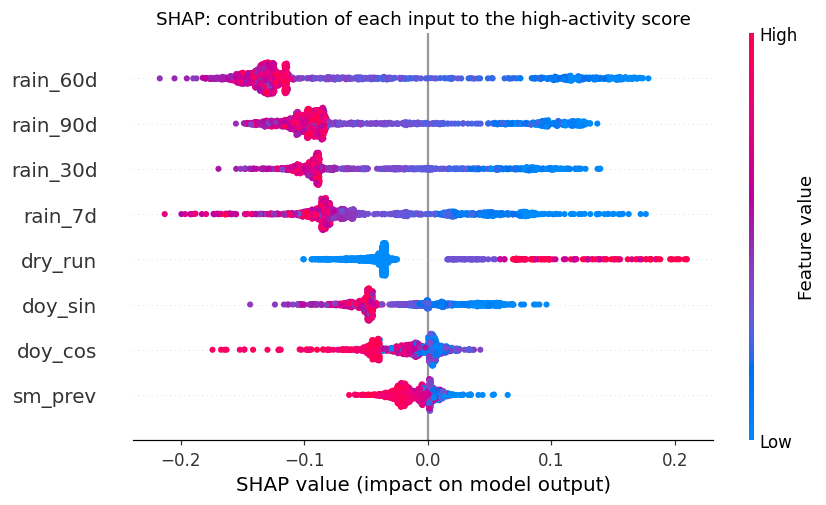

Mean |SHAP| per feature (larger = more influence on the model):
rain_60d    0.120
rain_90d    0.092
rain_30d    0.082
rain_7d     0.074
dry_run     0.050
doy_sin     0.043
doy_cos     0.023
sm_prev     0.015
dtype: float64

Week of 2015-09-16: pushes score DOWN: doy_cos (+0.01), sm_prev (+0.01) | pushes score UP: rain_60d (+0.14), rain_90d (+0.11)

Week of 2019-09-18: pushes score DOWN: sm_prev (+0.01), doy_cos (+0.01) | pushes score UP: rain_60d (+0.12), rain_90d (+0.10)

Week of 2022-02-16: pushes score DOWN: rain_60d (-0.13), rain_90d (-0.10) | pushes score UP: sm_prev (-0.02), doy_cos (-0.03)


In [24]:
# 22. SHAP: how each input pushed the model's high-activity score up or down (explains model behaviour, NOT causes).
# Uses the final model from cell 17 (`final`, features `final_cols`). Past weeks are in-sample, so this describes the model, not forecast skill.
import shap
Xs = D[final_cols]
expl = shap.TreeExplainer(final)
sv = expl.shap_values(Xs, check_additivity=False)
if isinstance(sv, list):          # older shap: list of arrays, one per class
    sv = sv[1]
elif getattr(sv, "ndim", 2) == 3: # newer shap: (rows, features, classes)
    sv = sv[:, :, 1]

shap.summary_plot(sv, Xs, show=False, max_display=len(final_cols))
plt.title("SHAP: contribution of each input to the high-activity score")
plt.tight_layout(); plt.savefig("fig_shap_summary.png", dpi=200); plt.show()

mean_abs = pd.Series(np.abs(sv).mean(axis=0), index=final_cols).sort_values(ascending=False).round(3)
print("Mean |SHAP| per feature (larger = more influence on the model):"); print(mean_abs)

for dte in ["2015-09-15", "2019-09-15", "2022-02-15"]:                  # a dry-year week, another dry-year week, a wet-season week
    i = Xs.index.get_indexer([pd.Timestamp(dte)], method="nearest")[0]
    contrib = pd.Series(sv[i], index=final_cols).sort_values()
    print(f"\nWeek of {Xs.index[i].date()}: pushes score DOWN: {', '.join(f'{k} ({v:+.2f})' for k, v in contrib.head(2).items())}"
          f" | pushes score UP: {', '.join(f'{k} ({v:+.2f})' for k, v in contrib.tail(2)[::-1].items())}")


## Notes for the write-up
- Correlation is not causation. FIRMS shows satellite detections, not every fire, and no detection does not prove no fire.
- Area-average rainfall cannot say *where*. Fire detections are inside the same rectangular box, which is larger than the province.
- Report only the numbers printed above. Save the figures (`fig_*.png`) and the trend table for the slides.